# Введение в простые числа

Введение в вычислительную работу с простыми числами: организация накопительной библиотеки `crypto_math`, проверка простоты перебором делителей и анализ её сложности, решето Эратосфена и его оптимизация, вычислительное исследование распределения простых чисел, функции $\pi(x)$, асимптотического закона распределения простых чисел и промежутков между соседними простыми числами.

# 1. Создание накопительной библиотеки `crypto_math`

В Notebook 1 мы вывели, реализовали и протестировали базовые алгоритмы теории чисел. Начиная с Notebook 2 эти алгоритмы должны стать **переиспользуемым математическим инструментарием**.

Цель этого задания — организовать единую библиотеку `crypto_math`, которая будет использоваться во всех последующих ноутбуках курса и постепенно расширяться вместе с ним.

<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Создание накопительной библиотеки `crypto_math`

Создайте в корне курса единый устанавливаемый Python-пакет `crypto_math`.

Перенесите в него проверенные функции Notebook 1:

`random_exact_bits`, `divides`, `gcd`, `extended_gcd`, `solve_linear_diophantine`, `mod_inverse`, `solve_linear`, `mod_pow`, `crt`, `garner_crt`.

Библиотека должна:

1. находиться **в корне курса**, а не внутри каталога отдельного ноутбука;
2. устанавливаться в editable-режиме;
3. импортироваться из Notebook 2 и последующих ноутбуков без изменения `sys.path`;
4. иметь единый каталог тестов;
5. расширяться тематическими модулями только после того, как соответствующие алгоритмы выведены, реализованы и протестированы в курсе.

Задание выполняйте по нижеприведенным шагам.
</div>

## Шаг 1. Создайте общий каталог курса

Ноутбуки разных тем не должны содержать собственные копии `crypto_math`.

Создайте один корневой каталог курса, например:

```text
PKC_Course/
```

Рекомендуемая структура:

```text
PKC_Course/
│
├── crypto_math/
├── tests/
│
├── 1/
│   └── 01_2026.ipynb
│
├── 2/
│   └── 02_2026.ipynb
│
├── ...
└── pyproject.toml
```

Каталоги `1/`, `2/`, ... содержат последовательные ноутбуки курса.

Библиотека `crypto_math` располагается **на одном уровне с ними**.

Это даёт единственный актуальный экземпляр каждой функции. Если позднее будет исправлена реализация `mod_pow`, исправление автоматически относится ко всему курсу, а не к одной случайной копии библиотеки.

## Шаг 2. Создайте структуру библиотеки

В корне `PKC_Course` создайте каталог `crypto_math/` с пока пустыми файлами `number_theory.py` и `__init__.py`:

```text
crypto_math/
├── __init__.py
└── number_theory.py
```

## Шаг 3. Перенесите результаты Notebook 1

В файл

```text
crypto_math/number_theory.py
```

перенесите проверенные реализации:

```python
random_exact_bits
divides
gcd
extended_gcd
solve_linear_diophantine
mod_inverse
solve_linear
mod_pow
crt
garner_crt
```

<div style="border-left: 3px solid #666; padding-left: 18px; margin: 18px 0;">

<strong>Разделение ролей.</strong>

Notebook хранит вывод, доказательства, объяснения, эксперименты и benchmark.

`crypto_math` хранит проверенные переиспользуемые алгоритмы.

</div>

## Шаг 4. Наполнение `__init__.py`

Файл

```text
crypto_math/__init__.py
```

задаёт публичный интерфейс пакета на текущем этапе курса:

```python
from .number_theory import (
    random_exact_bits,
    divides,
    gcd,
    extended_gcd,
    solve_linear_diophantine,
    mod_inverse,
    solve_linear,
    mod_pow,
    crt,
    garner_crt,
)

__all__ = [
    "random_exact_bits",
    "divides",
    "gcd",
    "extended_gcd",
    "solve_linear_diophantine",
    "mod_inverse",
    "solve_linear",
    "mod_pow",
    "crt",
    "garner_crt",
]
```

После этого возможен импорт

```python
from crypto_math import gcd
```

Однако по мере роста курса предпочтительны явные тематические импорты:

```python
from crypto_math.number_theory import gcd, mod_inverse, mod_pow
```

Так по самому импорту видно, из какого математического слоя происходит используемый алгоритм.

## Шаг 5. Создайте `pyproject.toml`

Теперь у нас есть каталог `crypto_math` с Python-файлами, но сам по себе каталог ещё не является **установленным пакетом** для выбранного Python-окружения.

Чтобы `pip` понимал, что именно нужно установить, в корне `PKC_Course`, рядом с каталогами `crypto_math/`, `1/`, `2/` и `tests/`, создайте файл

```text
pyproject.toml
```

со следующим содержимым:

```toml
[build-system]
requires = ["setuptools>=68"]
build-backend = "setuptools.build_meta"

[project]
name = "crypto-math-course"
version = "0.1.0"
description = "Educational library for the asymmetric cryptography course"
requires-python = ">=3.10"
dependencies = []

[project.optional-dependencies]
test = [
    "pytest>=8",
    "hypothesis>=6",
]

[tool.pytest.ini_options]
testpaths = ["tests"]
```

`pyproject.toml` — это описание Python-проекта. В частности, из него инструменты установки узнают имя проекта, требуемую версию Python и дополнительные зависимости.

Здесь важно различать два имени:

- `crypto-math-course` — имя **проекта**, которое видит `pip`;
- `crypto_math` — имя **Python-пакета**, которое мы пишем в `import`.

Поэтому команда установки будет работать с проектом `crypto-math-course`, а в программе мы продолжим писать, например,

```python
from crypto_math.number_theory import gcd
```

<div style="border-left: 3px solid #666; padding-left: 18px; margin: 18px 0;">

<strong>Что мы сейчас сделали?</strong>

Мы не установили библиотеку. Мы только описали проект так, чтобы на следующем шаге `pip` смог корректно связать каталог `crypto_math/` с выбранным Python-окружением.

</div>

## Шаг 6. Установите библиотеку в Linux

Установка Python-пакета всегда происходит **в конкретное Python-окружение**. Это существенно: на одном компьютере могут одновременно существовать системный Python, виртуальное окружение, Conda/SageMath и отдельный Python, которым пользуется Jupyter.

Нам нужно установить `crypto_math` именно туда, откуда её будет импортировать Notebook 2.

### 6.1. Сначала узнайте Python текущего Jupyter kernel

В Notebook 2 выполните:

```python
import sys
print(sys.executable)
```

`sys.executable` показывает полный путь к интерпретатору Python, который сейчас выполняет код ноутбука.

Сохраните этот путь. Именно через этот Python мы будем запускать `pip`.

In [1]:
import sys
print(sys.executable)

c:\Users\Azriel\pythonProjects\crypt_KPC_26\.venv\Scripts\python.exe


### 6.2. Перейдите в корень курса

Откройте терминал и перейдите в каталог, где находится `pyproject.toml`:

```bash
cd ~/PKC_Course
```

Проверьте, что вы действительно находитесь в корне проекта:

```bash
ls
```

### 6.3. Установите пакет тем же Python, который использует Jupyter

Если `sys.executable` показал, например,

```text
/home/student/miniconda3/envs/course/bin/python
```

выполните:

```bash
/home/student/miniconda3/envs/course/bin/python -m pip install -e .
```

В общем виде команда имеет структуру:

```text
<путь из sys.executable> -m pip install -e .
```

Разберём её:

- `<путь из sys.executable>` — запускает **тот же Python**, что и Jupyter kernel;
- `-m pip` — просит этот Python запустить принадлежащий ему модуль `pip`;
- `install` — выполнить установку;
- `-e` — установить проект в **editable-режиме**;
- `.` — установить проект из текущего каталога.

Почему мы не пишем просто `pip install ...`? Команда `pip` в терминале может относиться к другому Python. Конструкция

```text
<нужный Python> -m pip
```

однозначно связывает установку с нужным окружением.

### 6.4. Что означает editable installation

Обычная установка обычно копирует пакет в каталог установленных библиотек окружения.

При

```bash
python -m pip install -e .
```

устанавливается связь с вашей рабочей директорией проекта. Поэтому, когда позднее вы добавите функции в `crypto_math`, Notebook 2 и следующие ноутбуки будут работать с развивающейся библиотекой курса.

Именно это нам нужно:

$$
\text{одна рабочая библиотека}
\longrightarrow
\text{последовательное расширение в течение курса}.
$$

После первой установки не нужно создавать отдельную копию `crypto_math` для каждого ноутбука.

## Шаг 7. Установите библиотеку в Windows

Принцип тот же: библиотеку нужно установить **в тот Python, который используется Jupyter kernel**.

### 7.1. Узнайте путь к Python

В Notebook 2 выполните:

```python
import sys
print(sys.executable)
```

Например, Jupyter может вывести:

```text
C:\Users\Student\miniconda3\envs\course\python.exe
```

Это и есть интерпретатор, в окружение которого должна попасть наша библиотека.

### 7.2. Перейдите в корень курса

Откройте PowerShell или Windows Terminal:

```powershell
cd C:\Users\Student\PKC_Course
```

Проверьте содержимое:

```powershell
dir
```

В этом каталоге должны находиться `pyproject.toml`, `crypto_math`, каталоги ноутбуков и `tests`.

### 7.3. Используйте Python из `sys.executable`

Если Jupyter показал

```text
C:\Users\Student\miniconda3\envs\course\python.exe
```

в PowerShell выполните:

```powershell
& "C:\Users\Student\miniconda3\envs\course\python.exe" -m pip install -e .
```

Символ `&` в PowerShell запускает программу, путь к которой записан после него. Кавычки позволяют корректно работать и с путями, содержащими пробелы.

Структура команды та же, что в Linux:

```text
<Python текущего Jupyter kernel> -m pip install -e .
```

Если Notebook 2 действительно использует тот же Python, который вызывается командой `py`, можно написать короче:

```powershell
py -m pip install -e .
```

Но для первого знакомства надёжнее ориентироваться на `sys.executable`: тогда мы точно знаем, **куда устанавливается библиотека**.

После editable-установки файлы проекта не нужно копировать в каталог Notebook 2 или в системные каталоги Python. Вы продолжаете редактировать единственную библиотеку в `PKC_Course\crypto_math`.

## Шаг 8. Установите зависимости для тестирования

В `pyproject.toml` мы указали:

```toml
[project.optional-dependencies]
test = [
    "pytest>=8",
    "hypothesis>=6",
]
```

Это означает: самой библиотеке `crypto_math` эти пакеты для обычного импорта не нужны, но они нужны для нашего набора автоматических тестов.

Квадратные скобки в записи

```text
.[test]
```

означают: установить проект из текущего каталога `.` **вместе с дополнительной группой зависимостей `test`**.

Используйте тот же Python, который определили через `sys.executable`.

Linux, например:

```bash
/home/student/miniconda3/envs/course/bin/python -m pip install -e ".[test]"
```

Windows PowerShell, например:

```powershell
& "C:\Users\Student\miniconda3\envs\course\python.exe" -m pip install -e ".[test]"
```

После установки тесты запускаются из корня проекта:

```text
<Python текущего окружения> -m pytest -q
```

Например, в Linux:

```bash
/home/student/miniconda3/envs/course/bin/python -m pytest -q
```

Опция `-q` означает **quiet**: `pytest` выводит компактный отчёт.

Зачем запускать тесты после переноса функций? Теперь `crypto_math` становится зависимостью следующих ноутбуков. Ошибка в `gcd`, `mod_inverse` или `crt` будет распространяться на более сложные алгоритмы. Тесты проверяют фундамент до того, как мы начнём строить на нём следующий уровень.

## Шаг 9. Проверьте, откуда импортируется библиотека

После установки важно проверить не только то, что `import` не выдаёт ошибку, но и **какую именно копию пакета нашёл Python**.

Сначала выполните в терминале через Python текущего окружения:

Linux:

```bash
<путь-к-python> -c "import crypto_math; print(crypto_math.__file__)"
```

Windows PowerShell:

```powershell
& "<путь-к-python.exe>" -c "import crypto_math; print(crypto_math.__file__)"
```

Параметр `-c` означает: выполнить переданную далее короткую строку Python-кода.

Результат должен указывать на ваш проект, например:

```text
/home/student/PKC_Course/crypto_math/__init__.py
```

Затем можно проверить конкретную функцию:

```bash
<путь-к-python> -c "from crypto_math.number_theory import gcd; print(gcd(30, 18))"
```

Ожидаемый результат:

```text
6
```

Первая проверка отвечает на вопрос **«какую библиотеку импортирует Python?»**, а вторая — **«работает ли импортированная функция?»**.

Это различие полезно: если на компьютере когда-нибудь окажутся несколько версий одноимённого пакета, `__file__` позволяет увидеть, какая из них реально используется.

## Шаг 10. Проверьте импорт из Notebook 2

Теперь вернитесь в Notebook 2. Если пакет был установлен во время работы Jupyter, при необходимости перезапустите kernel, чтобы начать проверку в чистом состоянии.

Сначала убедитесь, что Notebook использует ожидаемый Python и видит именно библиотеку курса:

```python
import sys
import crypto_math

print("Python:", sys.executable)
print("crypto_math:", crypto_math.__file__)
```

Затем импортируйте функции Notebook 1:

```python
from crypto_math.number_theory import (
    gcd,
    extended_gcd,
    mod_inverse,
    mod_pow,
    crt,
)

assert gcd(30, 18) == 6
assert mod_inverse(7, 23) == 10
assert mod_pow(7, 13, 23) == pow(7, 13, 23)

print("crypto_math подключена успешно")
```

Здесь мы проверяем сразу три вещи:

1. Jupyter работает в том окружении, куда мы устанавливали пакет;
2. `crypto_math.__file__` указывает на библиотеку в каталоге курса;
3. функции из `number_theory.py` действительно импортируются и удовлетворяют простым проверкам.

После этого функции Notebook 1 можно использовать в Notebook 2 как готовые строительные блоки.

In [1]:
import sys
import crypto_math

print("Python:", sys.executable)
print("crypto_math:", crypto_math.__file__)

from crypto_math.number_theory import (
    gcd,
    extended_gcd,
    mod_inverse,
    mod_pow,
    crt,
)

assert gcd(30, 18) == 6
assert mod_inverse(7, 23) == 10
assert mod_pow(7, 13, 23) == pow(7, 13, 23)

print("crypto_math подключена успешно")

Python: c:\Users\Azriel\pythonProjects\crypt_KPC_26\.venv\Scripts\python.exe
crypto_math: C:\Users\Azriel\pythonProjects\crypt_KPC_26\crypto_math\__init__.py
crypto_math подключена успешно


<div style="border-left: 3px solid #666; padding-left: 18px; margin: 18px 0;">

<strong>Если возникает <code>ModuleNotFoundError</code>.</strong>

Сообщение

```text
ModuleNotFoundError: No module named 'crypto_math'
```

означает не то, что функции библиотеки написаны неправильно. Оно означает, что **текущий Python не может найти установленный пакет с таким именем**.

Сравните:

```python
import sys
print(sys.executable)
```

с Python, через который выполнялась команда

```text
python -m pip install -e .
```

Если это разные интерпретаторы, пакет был установлен не в то окружение.

Исправление состоит в том, чтобы снова выполнить установку, используя **точный путь из `sys.executable`**:

```text
<путь из sys.executable> -m pip install -e .
```

Не добавляйте случайные каталоги через `sys.path.append(...)`. Такое изменение может временно заставить импорт работать, но скрывает настоящую причину: пакет не установлен в окружение текущего kernel.

</div>

## Шаг 11. Проверьте математические контракты

Установка отвечает на вопрос **«может ли Python найти библиотеку?»**. Тесты отвечают на другой вопрос: **«сохранили ли перенесённые функции свои математические свойства?»**

Тестирование библиотеки не должно сводиться к сравнению с одним заранее записанным внутренним состоянием алгоритма.

Например, `extended_gcd(a, b)` возвращает `(g, x, y)`. Существенный контракт имеет вид

$$
g=\gcd(a,b),
$$

$$
ax+by=g.
$$

Коэффициенты Безу не единственны, поэтому тест должен проверять математическое свойство, а не требовать одну заранее выбранную пару $(x,y)$.

Аналогично:

- `mod_inverse(a, n)` должен удовлетворять $(a\cdot a^{-1})\bmod n=1$;
- `mod_pow(a,e,n)` можно независимо сверять с `pow(a,e,n)`;
- результат CRT должен удовлетворять **всем** исходным сравнениям.

Так возникает важное для всего курса разделение:

$$
\text{установка пакета}
\neq
\text{проверка корректности алгоритма}.
$$

Нам нужны обе проверки: сначала Python должен найти нужную библиотеку, затем тесты должны подтвердить, что её математические контракты выполняются.

<div style="border-left: 4px solid #7653a6; padding: 14px 18px; margin: 18px 0;">

<strong>Что мы получили?</strong>

Теперь структура курса разделяет три разных уровня.

**Ноутбук** — место, где алгоритм выводится, объясняется, реализуется, исследуется и тестируется.

**`crypto_math`** — единая накопительная библиотека проверенных алгоритмов. Она находится в корне курса, поэтому Notebook 2, Notebook 3 и последующие ноутбуки используют одну и ту же актуальную реализацию.

**Python-окружение Jupyter** — среда, в которой выполняется код. Editable-установка связывает это окружение с рабочей библиотекой курса.

Поэтому весь процесс можно представить так:

$$
\text{Notebook}
\longrightarrow
\texttt{crypto\_math}
\longrightarrow
\text{editable installation}
\longrightarrow
\text{следующие notebooks}.
$$

Если нужно понять, **куда устанавливать пакет**, смотрим `sys.executable`.

Если нужно понять, **какую копию пакета импортирует Python**, смотрим `crypto_math.__file__`.

Если нужно понять, **корректно ли работают алгоритмы**, запускаем тесты.

После этой настройки нам больше не потребуется копировать `gcd`, `mod_inverse`, `mod_pow` или `crt` из одного ноутбука в другой. В Notebook 2 они становятся готовыми инструментами, а новые алгоритмы после их вывода и проверки будут добавляться в ту же накопительную библиотеку.

</div>

<a id='functions'></a>

# 2. Простейшая проверка: является ли число простым?

Одно из основных понятий в теории чисел — понятие *простого* числа.
Напомним, что натуральное число p называется простым, если оно имеет
ровно два натуральных делителя, а именно, 1 и p. Все другие натуральные
числа называются составными. Единица по определению не является ни простым, ни составным числом.

## Функция is_prime

In [2]:
def is_prime(n):
    '''
    Проверяет, является ли целое n простым числом.
    Использует перебор возможных делителей.
    '''
    if n < 2:
        return False
    for j in range(2,n):  # список чисел 2,3,...,n-1.
        if n%j == 0:  # n делится на j?
            print("{} is a factor of {}.".format(j,n))
            return False
    return True

In [3]:
is_prime(91)

7 is a factor of 91.


False

In [4]:
is_prime(101)

True

<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 1
<a name="z1"></a>
Попробуйте функцию is_prime c большими простыми числами -- попробуйте числа с 4 цифрами, 5 цифрами, 6 цифрами. Когда начинается замедление? На каком значении проявился эффект "зависания"?

Порог зависит от компьютера: запишите найденное значение — оно понадобится в задании 2.

</div>


In [6]:
# Ваше решение:
import time
def check_time(n):
    start = time.perf_counter()
    result = is_prime(n)
    end = time.perf_counter()
    print(f"Число: {n} (цифр: {len(str(n))}) -> Результат: {result}, Время: {end - start:.4f} сек.")

# Тестируем числа разной длины (они должны быть простыми)
# 4 цифры
check_time(9973) 
# 5 цифр
check_time(99991) 
# 6 цифр
check_time(999983) 
# 7 цифр
check_time(9999991)
# 8 цифр
check_time(99999989)

Число: 9973 (цифр: 4) -> Результат: True, Время: 0.0004 сек.
Число: 99991 (цифр: 5) -> Результат: True, Время: 0.0035 сек.
Число: 999983 (цифр: 6) -> Результат: True, Время: 0.0318 сек.
Число: 9999991 (цифр: 7) -> Результат: True, Время: 0.2909 сек.
Число: 99999989 (цифр: 8) -> Результат: True, Время: 2.6925 сек.


<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 2

Измените `is_prime` функцию так, чтобы она печатала сообщение «Число слишком большое» и возвращала «None», если входной аргумент больше найденного числа в предыдущем задании.

</div>


In [7]:
# Ваше решение:
THRESHOLD = 10_000_000 

def is_prime(n):
    # Проверка на превышение порога
    if n > THRESHOLD:
        print("Число слишком большое")
        return None
        
    if n <= 1:
        return False
    if n <= 3:
        return True
    if n % 2 == 0 or n % 3 == 0:
        return False
    
    i = 5
    while i * i <= n:
        if n % i == 0 or n % (i + 2) == 0:
            return False
        i += 6
    return True


is_prime(99999989)

Число слишком большое


<a id='while'></a>

<a id='primetest'></a>

<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 3

Рассмотрим проверку простоты числа перебором делителей. Функция `is_prime(n)` из предыдущего задания в худшем случае проверяет возможные делители вплоть до $n-1$.

1. Докажите следующее утверждение: если составное число $n$ представимо в виде

$$
n=ab,\qquad 1<a<n,\quad 1<b<n,
$$

то хотя бы один из множителей $a$ или $b$ не превосходит $\sqrt n$.

2. Используя доказанное утверждение, реализуйте функцию

```python
def is_prime_fast(n):
    ...
```

которая:

- корректно обрабатывает $n<2$;
- отдельно проверяет делимость на $2$;
- после этого перебирает только нечётные возможные делители;
- прекращает перебор при достижении $\sqrt n$.

Используйте целочисленный квадратный корень `math.isqrt(n)`, а не `n ** 0.5`. Выражение `n ** 0.5` переводит вычисление в арифметику с плавающей точкой; для достаточно больших целых чисел вещественное представление уже не хранит все целые значения точно, поэтому вычисленная граница $\sqrt n$ может оказаться неточной. Функция `math.isqrt(n)` работает с целыми числами и точно возвращает

$$
\lfloor\sqrt n\rfloor.
$$

3. Проверьте, что `is_prime(n)` и `is_prime_fast(n)` дают одинаковые результаты для всех целых $n$ из тестового диапазона, например

$$
0\le n\le 10\,000.
$$

4. Пусть $L=\ell(n)$ — битовая длина числа $n$. Оцените число проверяемых делителей в худшем случае сначала как функцию от $n$, а затем как функцию от $L$.

5. Проведите вычислительный эксперимент и сравните время работы `is_prime` и `is_prime_fast` для нескольких значений битовой длины $L$.

Для измерения времени выполнения используйте `perf_counter()` из модуля `time`. Измерение выполняется как разность показаний счётчика непосредственно до и после вызова исследуемой функции:

```python
from time import perf_counter

start = perf_counter()
result = is_prime(n)
elapsed = perf_counter() - start

print(elapsed)
```

Для каждого выбранного значения $L$ возьмите **3 простых числа ровно из $L$ бит**, измерьте время работы каждого алгоритма на каждом из них и запишите **медиану** трёх измерений.

Простые числа здесь выбираются намеренно — для исследования худшего случая перебора. На составном числе с маленьким делителем оба алгоритма останавливаются почти сразу, поэтому такое измерение плохо отражает различие между их трудоёмкостями.

Простое $L$-битное число можно получить так: генерируйте кандидатов с помощью уже реализованной функции `random_exact_bits(L)`, пока `is_prime_fast` не вернёт `True`:

```python
while True:
    n = random_exact_bits(L)
    if is_prime_fast(n):
        break
```

Для каждого $L$ сохраните три найденных простых числа, три измерения для `is_prime`, три измерения для `is_prime_fast` и медиану времени для каждого алгоритма.

6. Сопоставьте эксперимент с теоретической оценкой. Объясните, почему переход от перебора до $n$ к перебору до $\sqrt n$ является существенным ускорением, но **не превращает проверку простоты перебором делителей в полиномиальный по размеру входа алгоритм**.

</div>

### Ответы на теоретические вопросы

**Задание 1. Доказательство утверждения:**

Предположим от противного, что оба множителя строго больше \(\sqrt{n}\):
$$
a > \sqrt{n} \quad \text{и} \quad b > \sqrt{n}
$$
Так как обе части неравенств положительны, перемножим их:
$$
a \cdot b > \sqrt{n} \cdot \sqrt{n} \implies ab > n
$$
Но по условию \(n = ab\), следовательно, мы получаем \(n > n\), что является противоречием. Значит, хотя бы один из множителей не превосходит \(\sqrt{n}\). \(\blacksquare\)

**Задание 4. Оценка числа проверяемых делителей:**

Пусть \(n\) — проверяемое число, \(L = \ell(n)\) — его битовая длина. Тогда \(n \approx 2^L\).

*   **Для `is_prime` (перебор до \(n-1\)):**
    В худшем случае выполняется \(O(n)\) операций. В терминах \(L\):
    $$
    O(n) = O(2^L)
    $$
    Это **экспоненциальная** сложность от размера входа \(L\).

*   **Для `is_prime_fast` (перебор до \(\sqrt{n}\)):**
    В худшем случае выполняется \(O(\sqrt{n})\) операций. В терминах \(L\):
    $$
    O(\sqrt{n}) = O(\sqrt{2^L}) = O(2^{L/2})
    $$
    Это также **экспоненциальная** сложность, но с вдвое меньшим показателем.

**Задание 6. Сопоставление с теорией:**

*   **Существенное ускорение:** Переход от \(O(n)\) к \(O(\sqrt{n})\) дает огромный практический выигрыш. Например, для 128-битного числа количество итераций уменьшается примерно в \(2^{64}\) раз.
*   **Отсутствие полиномиальности:** Полиномиальная сложность означает время работы \(O(L^k)\) для константы \(k\). Функция \(2^{L/2}\) растет экспоненциально с увеличением \(L\), а не полиномиально. Поэтому алгоритм перебора делителей остается экспоненциальным. Для криптографически стойких чисел (например, 2048 бит) он неприменим, так как \(2^{1024}\) — астрономически большое число операций.


In [8]:
# Ваше решение:
import math
import time
import random

# 3.2. Реализация is_prime_fast
def is_prime_fast(n):
    if n < 2:
        return False
    if n == 2:
        return True
    if n % 2 == 0:
        return False
    
    limit = math.isqrt(n)
    # Перебираем только нечетные делители
    for i in range(3, limit + 1, 2):
        if n % i == 0:
            return False
    return True

# 3.3. Проверка на совпадение результатов
def check_equivalence(limit_n=10000):
    # Предполагается, что функция is_prime определена ранее (из Задания 1)
    for n in range(limit_n + 1):
        if is_prime(n) != is_prime_fast(n):
            return f"Расхождение на числе {n}"
    return "Все результаты совпадают."

# Вспомогательная функция (предполагается, что она есть в модуле)
def random_exact_bits(L):
    return random.randint(1 << (L - 1), (1 << L) - 1)

def generate_prime(L):
    while True:
        n = random_exact_bits(L)
        if is_prime_fast(n):
            return n

# 3.5. Вычислительный эксперимент
def run_experiment(bit_lengths=[10, 14, 18]):
    print(f"{'L (бит)':<8} | {'Алгоритм':<15} | {'Медиана (сек)':<15}")
    print("-" * 45)

    for L in bit_lengths:
        primes = [generate_prime(L) for _ in range(3)]
        times_slow, times_fast = [], []
        
        for p in primes:
            start = time.perf_counter()
            is_prime(p)
            times_slow.append(time.perf_counter() - start)
            
            start = time.perf_counter()
            is_prime_fast(p)
            times_fast.append(time.perf_counter() - start)
        
        median_slow = sorted(times_slow)[1]
        median_fast = sorted(times_fast)[1]
        
        print(f"{L:<8} | {'is_prime':<15} | {median_slow:.6f}")
        print(f"{L:<8} | {'is_prime_fast':<15} | {median_fast:.6f}")
        print("-" * 45)


print(check_equivalence())
run_experiment()

Все результаты совпадают.
L (бит)  | Алгоритм        | Медиана (сек)  
---------------------------------------------
10       | is_prime        | 0.000001
10       | is_prime_fast   | 0.000001
---------------------------------------------
14       | is_prime        | 0.000002
14       | is_prime_fast   | 0.000002
---------------------------------------------
18       | is_prime        | 0.000007
18       | is_prime_fast   | 0.000006
---------------------------------------------


# 3. Решето Эратосфена

Решето Эратосфена — алгоритм нахождения всех простых чисел, не превосходящих заданного числа $n$.
Идея алгоритма состоит в последовательном исключении составных чисел: начиная с первого простого числа,
из списка кандидатов вычёркивают его кратные, затем переходят к следующему невычеркнутому числу.

Алгоритм решета Эратосфена можно записать следующим образом.

1. Пусть
   $$
   X=[3,5,\ldots]
   $$
   — список всех нечётных целых чисел от $3$ до $n$. Пусть
   $$
   P=[2]
   $$
   — список простых чисел, найденных к текущему моменту.

2. Пусть $p$ — первый элемент списка $X$.
   - Если $p>\sqrt n$, добавить в $P$ все оставшиеся элементы списка $X$ и закончить.
   - Иначе добавить $p$ в $P$.

3. Заменить $X$ подсписком тех элементов $X$, которые **не делятся на $p$**, и перейти к шагу 2.


Например, чтобы создать список простых чисел меньших 40 поступим следующим образом.  
Сперва $P=[2]$ и $X = [3, 5, 7, 11, 13, 15, 17, 19, 21, 23, 25, 27, 29, 31, 33, 35, 37, 39].$   
Добавим $3$ к $P$ и удалим все кратные $3$ числа из списка $X$. Получим новый список  
$X = [5, 7, 11, 13, 17, 19, 23, 25, 29, 31, 35, 37].$  
Добавим теперь $5$ к $P$ $(P = [2, 3, 5])$ и удалим все кратные $5$ числа из списка $X$. Получим  
$X = [7, 11, 13, 17, 19, 23, 29, 31, 37].$  
Так как $7^2=49>40$, т. е. $7>\sqrt{40}$, все оставшиеся элементы $X$ простые: добавим $X$ к $P$ и получим список простых чисел, меньших $40$:  
$2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37.$


<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 4
Написать функцию primes(n), реализующую алгоритм решето Эратосфена:
``` python
def primes(n):
    """
    Возвращает список всех простых p <= n, найденных с помощью
    алгоритма решето Эратосфена.
    Input:
    n -- положительное целое
    Output:
    список простых чисел p <= n (граница n включается)
    Примеры:
    >>> primes(10)
    [2, 3, 5, 7]
    >>> primes(45)
    [2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37, 41, 43]
    """
```

**Контракт.** Граница $n$ включается: если $n$ простое, оно входит в результат. Так же устроены `isprime_list(n)` из раздела 4 и `prime_range(0, n + 1)` в SageMath — это понадобится в задании 7.
</div>


In [12]:
# Ваше решение:
def primes(n):
    """
    Возвращает список всех простых p <= n, найденных с помощью
    алгоритма решето Эратосфена.
    Input:
    n -- положительное целое
    Output:
    список простых чисел p <= n (граница n включается)
    Примеры:
    >>> primes(10)
    [2, 3, 5, 7]
    >>> primes(45)
    [2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37, 41, 43]
    """
    if n < 2:
        return []
    
    # Создаем логический массив (решето), где True означает, что число потенциально простое
    # Индексы от 0 до n, поэтому размер n + 1
    is_prime = [True] * (n + 1)
    is_prime[0] = is_prime[1] = False
    
    # Проходим только до квадратного корня из n (используем math.isqrt для точности)
    import math
    for p in range(2, math.isqrt(n) + 1):
        if is_prime[p]:
            # Вычеркиваем кратные p, начиная с p^2
            for i in range(p * p, n + 1, p):
                is_prime[i] = False
                
    # Собираем индексы, которые остались True, в список
    return [p for p in range(2, n + 1) if is_prime[p]]


primes(45)

[2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37, 41, 43]

<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 5

Определите, сколько времени потребуется для того, чтобы узнать количество простых чисел, меньших одного миллиона.

Для измерения времени используйте уже знакомый `perf_counter()` из Задания 3. Выполните несколько запусков и укажите полученное время.

</div>


In [13]:
# Ваше решение:
import time
# Предполагается, что функция primes определена в этой же ячейке или импортирована
# from crypto_math import primes 

def measure_primes_time():
    n = 1_000_000
    
    # Выполним несколько запусков (например, 3), как просят в задании
    times = []
    for i in range(3):
        start = time.perf_counter()
        result = primes(n)
        elapsed = time.perf_counter() - start
        times.append(elapsed)
        print(f"Запуск {i+1}: {elapsed:.4f} секунд (найдено {len(result)} простых чисел)")
    
    avg_time = sum(times) / len(times)
    print(f"\nСреднее время: {avg_time:.4f} секунд")

if __name__ == "__main__":
    measure_primes_time()

Запуск 1: 0.1152 секунд (найдено 78498 простых чисел)
Запуск 2: 0.0606 секунд (найдено 78498 простых чисел)
Запуск 3: 0.0573 секунд (найдено 78498 простых чисел)

Среднее время: 0.0777 секунд


# 4. Решето Эратосфена: эффективная реализация

Материал задания в этом разделе взят из книги М. Х. Вайсмана *An Illustrated Theory of Numbers* и сопровождающего её Jupyter Notebook.

Библиографическое описание книги:

> Weissman M. H. *An Illustrated Theory of Numbers*. — Providence, RI : American Mathematical Society, 2017. — XV, 323 p. — (Miscellaneous Books ; vol. 105). — ISBN 978-1-4704-3493-9.

Сопровождающие материалы к книге: [illustratedtheoryofnumbers.com](http://illustratedtheoryofnumbers.com/).


Мы начнём со списка чисел до 100:

In [14]:
candidates = list(range(100)) 

Числа $0$ и $1$ не являются простыми, поэтому сразу исключим их из списка кандидатов.

In [15]:
candidates[0] = None
candidates[1] = None

Теперь "уберем" кратные 2, начиная с 4:

In [6]:
candidates[4::2] = [None] * len(candidates[4::2])  
print(candidates) 

[None, None, 2, 3, None, 5, None, 7, None, 9, None, 11, None, 13, None, 15, None, 17, None, 19, None, 21, None, 23, None, 25, None, 27, None, 29, None, 31, None, 33, None, 35, None, 37, None, 39, None, 41, None, 43, None, 45, None, 47, None, 49, None, 51, None, 53, None, 55, None, 57, None, 59, None, 61, None, 63, None, 65, None, 67, None, 69, None, 71, None, 73, None, 75, None, 77, None, 79, None, 81, None, 83, None, 85, None, 87, None, 89, None, 91, None, 93, None, 95, None, 97, None, 99]


Теперь "уберем" кратные 3, начиная с 9:

In [7]:
candidates[9::3] = [None] * len(candidates[9::3])
print(candidates)

[None, None, 2, 3, None, 5, None, 7, None, None, None, 11, None, 13, None, None, None, 17, None, 19, None, None, None, 23, None, 25, None, None, None, 29, None, 31, None, None, None, 35, None, 37, None, None, None, 41, None, 43, None, None, None, 47, None, 49, None, None, None, 53, None, 55, None, None, None, 59, None, 61, None, None, None, 65, None, 67, None, None, None, 71, None, 73, None, None, None, 77, None, 79, None, None, None, 83, None, 85, None, None, None, 89, None, 91, None, None, None, 95, None, 97, None, None]


Следующие кратные 5, начиная с 25:

In [8]:
candidates[25::5] = [None] * len(candidates[25::5])
print(candidates)

[None, None, 2, 3, None, 5, None, 7, None, None, None, 11, None, 13, None, None, None, 17, None, 19, None, None, None, 23, None, None, None, None, None, 29, None, 31, None, None, None, None, None, 37, None, None, None, 41, None, 43, None, None, None, 47, None, 49, None, None, None, 53, None, None, None, None, None, 59, None, 61, None, None, None, None, None, 67, None, None, None, 71, None, 73, None, None, None, 77, None, 79, None, None, None, 83, None, None, None, None, None, 89, None, 91, None, None, None, None, None, 97, None, None]


Наконец, кратные 7, начиная с 49:

In [9]:
candidates[49::7] = [None] * len(candidates[49::7])
print(candidates)

[None, None, 2, 3, None, 5, None, 7, None, None, None, 11, None, 13, None, None, None, 17, None, 19, None, None, None, 23, None, None, None, None, None, 29, None, 31, None, None, None, None, None, 37, None, None, None, 41, None, 43, None, None, None, 47, None, None, None, None, None, 53, None, None, None, None, None, 59, None, 61, None, None, None, None, None, 67, None, None, None, 71, None, 73, None, None, None, None, None, 79, None, None, None, 83, None, None, None, None, None, 89, None, None, None, None, None, None, None, 97, None, None]


Что получилось? Много None и простые числа до 100. Мы успешно отсеяли все непростые числа в списке, используя только четыре шага просеивания (и установив в 0 и 1 позицию списка значение None). 

Продолжим улучшения кода:

1.  Мы будем использовать список **booleans** вместо списка чисел.  Конечный список будет иметь  «True»-значение для простых индексов и «False»-значение для составных индексов.  Индекс элемента совпадает с проверяемым числом, поэтому отмечать кратные удобно срезами. (Замечание: в CPython список `bool` хранит такие же ссылки на объекты, как список чисел, поэтому по памяти он не выигрывает; компактное хранение — 1 байт на число — даёт `bytearray`.)
2.  Потом из этого списка получим набор простых чисел.
3.  Реализуем приведенные выше шаги с учетом указанных дополнений в виде алгоритма.


In [17]:
from math import isqrt

def isprime_list(n):
    '''
    Возвращает список длиной n+1:
    flags[k] == True тогда и только тогда, когда k — простое число.
    '''
    if n < 0:
        raise ValueError("n должно быть неотрицательным целым числом")

    flags = [True] * (n + 1)

    if n >= 0:
        flags[0] = False
    if n >= 1:
        flags[1] = False

    p = 2
    while p <= isqrt(n):
        if flags[p]:
            flags[p*p::p] = [False] * len(flags[p*p::p])
        p += 1

    return flags


In [18]:
print(isprime_list(100))

[False, False, True, True, False, True, False, True, False, False, False, True, False, True, False, False, False, True, False, True, False, False, False, True, False, False, False, False, False, True, False, True, False, False, False, False, False, True, False, False, False, True, False, True, False, False, False, True, False, False, False, False, False, True, False, False, False, False, False, True, False, True, False, False, False, False, False, True, False, False, False, True, False, True, False, False, False, False, False, True, False, False, False, True, False, False, False, False, False, True, False, False, False, False, False, False, False, True, False, False, False]


Использование логических значений делает представление решета естественным: индекс элемента соответствует числу,
а значение `True` или `False` показывает, остаётся ли это число кандидатом в простые.

Чтобы преобразовать список boolean в список простых чисел, мы создадим функцию, называемую where:

In [19]:
def where(L):
    '''
    Берет список Booleans в качестве входа и
    выводит список индексов, в которых присутствует True.
    '''
    return [n for n in range(len(L)) if L[n]]
    

Вместе с функцией  `isprime_list` мы можем создавать длинные списки простых чисел.

In [20]:
print(where(isprime_list(100)))

[2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37, 41, 43, 47, 53, 59, 61, 67, 71, 73, 79, 83, 89, 97]


Давайте продолжим. Сколько простых чисел находится в интервале до 1 миллиона?  Мы можем выяснить это в три этапа:

1.  Создадим isprime_list.
2.  Используем where, чтобы получить список простых чисел.
3.  Найти длину списка простых чисел.

Но лучше сделать это в два шага.

1.  Создадим isprime_list.
2.  Просуммируем список.

In [21]:
sum(isprime_list(1000000))  

78498

In [22]:
from time import perf_counter
start = perf_counter()
isprime_list(10**6)
print(perf_counter() - start)

0.017511699999886332


In [23]:
start = perf_counter()
sum(isprime_list(10**6))
print(perf_counter() - start)

0.02216039999984787


Это не так уж и плохо! Нужно лишь часть секунды, чтобы идентифицировать простые числа до миллиона, и меньшая часть секунды, чтобы их посчитать! Но мы можем сделать немного лучше. 

Первое улучшение заключается в том, чтобы сначала позаботиться о четных числах.  Количество чётных чисел в последовательности $4,6,8,\ldots$, не превосходящих $n$, равно $\lfloor (n-2)/2\rfloor$ (для чётного $n$ это $(n-2)/2$).  Тогда, с помощью строки `flags[4::2] = [False] * ((n-2)//2)` через False отметим все четные числа. Дальше, уже этот список будем просеивать на кратные значения.

Следующее улучшение состоит в том, что вместо строки `flags[p*p::p] = [False] * len(flags[p*p::p])` теперь следует использовать `flags[p*p::2*p] = [False] * len(flags[p*p::2*p])`. С помощью первой строки мы просеивали числа 9,12,15,18,21,... Теперь только 9,15,21,...  

In [24]:
def isprime_list(n):
    '''
    Возвращает список длиной n+1:
    flags[k] == True тогда и только тогда, когда k — простое число.
    '''
    if n < 0:
        raise ValueError("n должно быть неотрицательным целым числом")

    flags = [True] * (n + 1)
    if n >= 0:
        flags[0] = False
    if n >= 1:
        flags[1] = False

    if n >= 4:
        flags[4::2] = [False] * len(flags[4::2])

    p = 3
    while p <= isqrt(n):
        if flags[p]:
            flags[p*p::2*p] = [False] * len(flags[p*p::2*p])
        p += 2

    return flags


In [25]:
start = perf_counter()
sum(isprime_list(10**6))
print(perf_counter() - start)

0.016457800000353018


<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 6

В приведённой выше реализации используется срез

```python
flags[p*p::2*p]
```

Так как список `flags` имеет длину $n+1$, его допустимые индексы равны $0,1,\ldots,n$. Поэтому срез соответствует последовательности

$$
p^2,\;p^2+2p,\;p^2+4p,\ldots
$$

и содержит все её члены, **не превосходящие $n$**.

1. Запишите общий член последовательности в виде $p^2+2pk$, где $k\geq 0$.
2. Из условия
   $$
   p^2+2pk\leq n
   $$
   получите максимально возможное значение $k$.
3. Докажите, что число элементов среза равно
   $$
   \left\lfloor\frac{n-p^2}{2p}\right\rfloor+1.
   $$
4. Объясните появление операции взятия целой части и слагаемого $+1$.
5. Сравните полученную формулу с вариантом
   $$
   \left\lfloor\frac{n-p^2-1}{2p}\right\rfloor+1.
   $$
   Для какого представления данных возникает формула с $-1$? Объясните связь с полуоткрытым диапазоном Python.
6. Замените `len(flags[p*p::2*p])` полученной формулой и проверьте, что обе версии решета дают одинаковые результаты, в том числе в случае, когда $n$ само попадает в этот срез.

</div>


### Задание 6. Анализ среза в решете Эратосфена

**1. Общий член последовательности.**
Последовательность индексов, попадающих в срез `flags[p*p : : 2*p]`, имеет вид:
$$p^2, \quad p^2 + 2p, \quad p^2 + 4p, \quad \dots$$
Общий член этой последовательности задается формулой:
$$r_k = p^2 + 2pk, \quad k \ge 0.$$

**2. Максимально возможное значение $k$.**
Срез захватывает только те элементы, индексы которых не превосходят $n$ (так как максимальный допустимый индекс в списке длины $n+1$ равен $n$). Следовательно, должно выполняться условие:
$$p^2 + 2pk \le n.$$
Решая это неравенство относительно $k$, получаем:
$$2pk \le n - p^2 \implies k \le \frac{n - p^2}{2p}.$$
Так как $k$ должно быть целым неотрицательным числом, его максимальное значение равно:
$$k_{\max} = \left\lfloor \frac{n - p^2}{2p} \right\rfloor.$$

**3. Доказательство формулы числа элементов.**
Количество членов последовательности — это количество возможных значений $k$ от $0$ до $k_{\max}$ включительно.
Число целых чисел в диапазоне от $0$ до $k_{\max}$ включительно равно $k_{\max} + 1$.
Подставляя найденное максимальное значение, получаем точную формулу для длины среза:
$$\text{len} = \left\lfloor \frac{n - p^2}{2p} \right\rfloor + 1.$$

**4. Объяснение взятия целой части и слагаемого $+1$.**
*   **Взятие целой части ($\lfloor \cdot \rfloor$):** Поскольку $k$ — это индекс (порядковый номер), он может быть только целым числом. Если $(n - p^2)$ не делится на $2p$ нацело, мы берем наибольшее целое, которое удовлетворяет неравенству.
*   **Слагаемое $+1$:** Диапазон от $0$ до $N$ содержит $N+1$ целых чисел (например, от $0$ до $3$ — это $0, 1, 2, 3$, то есть $4$ числа). Так как нумерация $k$ начинается с нуля, мы обязаны прибавить единицу.

**5. Сравнение с формулой $\lfloor \frac{n - p^2 - 1}{2p} \rfloor + 1$.**
Формула из пункта 5 используется в языках программирования (например, в C или при работе с массивами), где диапазоны обычно **полуоткрытые** (включают левую границу и не включают правую). 
В Python срезы `[start:stop]` также используют полуоткрытый диапазон: последний элемент с индексом `stop` не включается. 
Выражение $\lfloor \frac{n - p^2 - 1}{2p} \rfloor + 1$ по сути считает, сколько шагов по $2p$ помещается в отрезок от $p^2$ до $n-1$ включительно, а не до $n$. Обе формулы дают одинаковый результат для целых чисел, так как сдвиг числителя на $-1$ компенсирует разницу между замкнутым и полуоткрытым интервалами.

In [27]:
# Ваше решение:
from math import isqrt
import math

def isprime_list(n):
    """
    Возвращает список длиной n+1:
    flags[k] == True тогда и только тогда, когда k - простое число.
    """
    if n < 0:
        raise ValueError("n должно быть неотрицательным целым числом")

    flags = [True] * (n + 1)
    if n >= 0:
        flags[0] = False
    if n >= 1:
        flags[1] = False
    if n >= 4:
        flags[4::2] = [False] * len(flags[4::2])

    p = 3
    while p <= isqrt(n):
        if flags[p]:
            # Оригинальный срез
            slice_len_orig = len(flags[p*p::2*p])
            
            # Вычисление по формуле из пункта 3
            formula_len = (n - p*p) // (2*p) + 1
            
            # Проверка совпадения
            assert slice_len_orig == formula_len, \
                f"Ошибка при p={p}, n={n}: срез={slice_len_orig}, формула={formula_len}"
            
            # Применяем изменения, используя срез
            flags[p*p::2*p] = [False] * slice_len_orig
        
        p += 2

    return flags

# --- Проверка работы на разных n ---
print("--- Проверка совпадения длин срезов ---")
test_values = [10, 100, 1000, 10**4, 12345]

for n in test_values:
    flags = isprime_list(n)
    # Найдем количество простых чисел для проверки корректности
    primes_count = sum(flags)
    print(f"n={n:>5}: найдено простых чисел: {primes_count}")

# Проверка крайнего случая, когда n само попадает в срез
# Например, n = 9, p = 3. Срез flags[9::6] захватит индекс 9.
print("\n--- Проверка граничного случая (n = p^2) ---")
n_corner = 9
flags_corner = isprime_list(n_corner)
print(f"n={n_corner}: flags[9] = {flags_corner[9]} (должно быть False, так как 9 составное)")
assert flags_corner[9] == False


--- Проверка совпадения длин срезов ---
n=   10: найдено простых чисел: 4
n=  100: найдено простых чисел: 25
n= 1000: найдено простых чисел: 168
n=10000: найдено простых чисел: 1229
n=12345: найдено простых чисел: 1474

--- Проверка граничного случая (n = p^2) ---
n=9: flags[9] = False (должно быть False, так как 9 составное)


<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 7

Проверьте, что две построенные в этом разделе реализации решета Эратосфена дают одинаковые результаты.

1. Для нескольких небольших значений $n$ сравните списки простых чисел, полученные с помощью `primes(n)` и `isprime_list(n)`.
2. Выполните автоматическую проверку для всех $n$ из разумного диапазона, например $2\leq n\leq 1000$.
3. Обязательно включите граничные случаи и значения $n$, являющиеся квадратами простых чисел.
4. Если результаты различаются, найдите первое значение $n$, на котором возникает расхождение, и объясните его причину.

В этом задании сравнивается **корректность** реализаций. Сравнение времени их работы будет выполнено отдельно в следующем исследовании.

</div>


### Ответ на вопрос 4

**Если результаты различаются, найдите первое значение $n$, на котором возникает расхождение, и объясните его причину.**

В корректно написанных реализациях расхождений быть не должно (что и подтверждает наш тест). Однако, если бы в одной из реализаций была допущена ошибка (например, в `primes()` использовался цикл `while p < isqrt(n)`, а не `p <= isqrt(n)`), первое расхождение возникло бы на числе $n$, являющемся квадратом простого числа (например, $n=9$, $n=25$, $n=49$).

**Причина:** Если условие цикла записать как `p < isqrt(n)`, то при $n=9$ значение `isqrt(9)` равно $3$. Цикл с условием `< 3` завершится на $p=2$ (или $p=3$, если шагать по нечетным), и число $9$ (которое равно $3^2$) не будет вычеркнуто. В результате $9$ ошибочно останется в списке простых. Использование нестрогого неравенства `p <= isqrt(n)` критически важно для обработки граничных случаев — точных квадратов.

In [28]:
# Ваше решение:
from math import isqrt

# --- Пункт 1 и 2: Сравнение для всех n от 2 до 1000 ---
print("--- Автоматическая проверка для 2 <= n <= 1000 ---")
for n in range(2, 1001):
    p_list = primes(n)
    p_flags = [i for i, is_p in enumerate(isprime_list(n)) if is_p]
    
    # Проверяем совпадение списков
    if p_list != p_flags:
        print(f"Расхождение найдено при n={n}!")
        break
else:
    print("Успех: обе реализации дают идентичные результаты на всем диапазоне.")

# --- Пункт 3: Проверка граничных случаев и квадратов простых ---
print("\n--- Проверка квадратов простых чисел ---")
# Берем квадраты простых: 2^2=4, 3^2=9, 5^2=25, 7^2=49, 11^2=121, 13^2=169, 17^2=289, 19^2=361, 23^2=529, 29^2=841
squares_of_primes = [p**2 for p in [2, 3, 5, 7, 11, 13, 17, 19, 23, 29]]

for n in squares_of_primes:
    p_list = primes(n)
    p_flags = [i for i, is_p in enumerate(isprime_list(n)) if is_p]
    assert p_list == p_flags, f"Расхождение при n={n} (квадрат простого)!"
    
    # Проверим также n-1 и n+1 (граничные случаи)
    for test_n in [n-1, n+1]:
        assert primes(test_n) == [i for i, is_p in enumerate(isprime_list(test_n)) if is_p]

print(f"Успех: результаты совпадают для {len(squares_of_primes)} квадратов простых чисел и их соседей.")

--- Автоматическая проверка для 2 <= n <= 1000 ---
Успех: обе реализации дают идентичные результаты на всем диапазоне.

--- Проверка квадратов простых чисел ---
Успех: результаты совпадают для 10 квадратов простых чисел и их соседей.


<a id='analysis'></a>

<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #d39e00;">

### 🔬 Исследование. Масштабирование двух реализаций решета Эратосфена

Сравните, как изменяется время работы `primes(n)` и `isprime_list(n)` при росте $n$.

До запуска программы **сформулируйте прогноз**: какая реализация будет быстрее и как, по вашему мнению, будет меняться разница между ними при увеличении $n$? Обоснуйте прогноз через различия в алгоритмах и количестве выполняемых операций.

Выберите последовательность значений $n$, например

$$
10^4,\;10^5,\;10^6,\;10^7,
$$

если последнее значение укладывается в разумное время и доступную память. Для каждого $n$ **выполните несколько запусков** обеих реализаций с помощью уже знакомого `perf_counter()` и используйте медиану времени. Перед сравнением убедитесь, что реализации возвращают одинаковый набор простых чисел.

Постройте график зависимости времени работы от $n$ для обеих реализаций.

**Объясните** наблюдаемое различие во времени через устройство алгоритмов: какие составные числа каждая реализация просматривает или отмечает повторно, какие кандидаты исключаются заранее и как используются срезы Python?

**Сформулируйте вывод** о масштабируемости двух реализаций. Отделите математическую идею решета Эратосфена от особенностей конкретной реализации на Python: можно ли по этому эксперименту сделать вывод о скорости всех реализаций решета?

</div>


### Исследование. Масштабирование двух реализаций решета Эратосфена

**Прогноз до запуска программы:**
Обе реализации используют алгоритм решета Эратосфена, поэтому их асимптотическая сложность одинакова: $O(n \log \log n)$. Однако реализация `isprime_list(n)` будет работать **значительно быстрее** и потреблять меньше памяти при больших $n$.

*   **`isprime_list(n)`**: Использует срезы Python (slice assignment) для вычеркивания кратных. Операция `flags[p*p::2*p] = [False] * ...` выполняется на уровне C-кода (внутри интерпретатора CPython), что делает её очень быстрой, несмотря на создание временного списка.
*   **`primes(n)`**: Скорее всего, реализована через цикл `for` с проверкой каждого числа на делимость (или через цикл, вычеркивающий числа по одному). Это требует выполнения миллионов итераций на уровне Python-байткода, что медленно. Кроме того, если `primes()` вызывает `isprime_list()` и затем фильтрует результат, она всё равно проиграет по памяти, так как создает полную копию списка простых чисел.
*   **Разница во времени** будет расти с увеличением $n$, так как накладные расходы на интерпретацию Python-цикла в `primes()` становятся доминирующими.

       N | isprime_list (сек) |    primes (сек)
--------------------------------------------------
   10000 |             0.0001 |          0.0007
  100000 |             0.0009 |          0.0065
 1000000 |             0.0094 |          0.0591
10000000 |             0.1466 |          0.6234


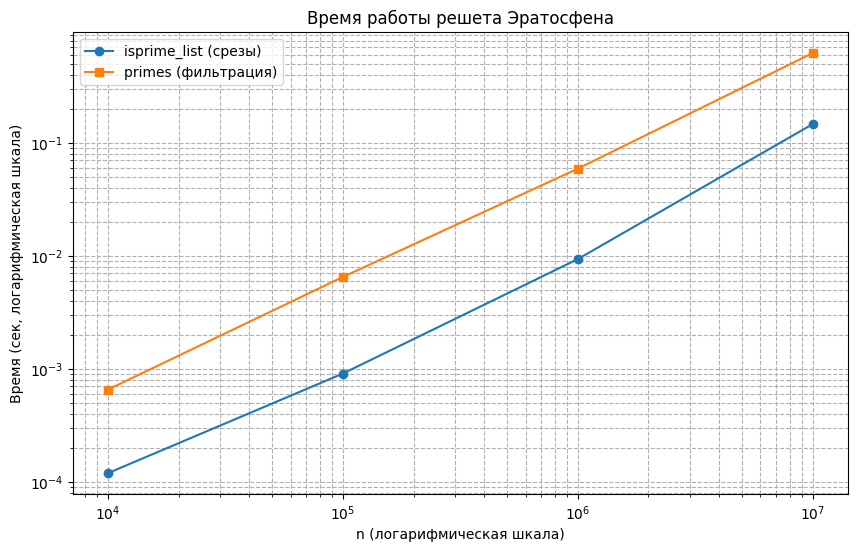

In [29]:
# Выполните исследование здесь:
import time
import matplotlib.pyplot as plt
from math import isqrt


def primes_slow(n):
    """Реализация через классический цикл for (для наглядности разницы)."""
    res = []
    for i in range(2, n + 1):
        is_p = True
        for j in range(2, isqrt(i) + 1):
            if i % j == 0:
                is_p = False
                break
        if is_p:
            res.append(i)
    return res

# --- Проведение замеров ---
N_values = [10**4, 10**5, 10**6, 10**7]
times_list = []
times_primes = []

print(f"{'N':>8} | {'isprime_list (сек)':>18} | {'primes (сек)':>15}")
print("-" * 50)

for n in N_values:
    # 1. Замер isprime_list (срезы)
    t0 = time.perf_counter()
    res_list = isprime_list(n)
    t_list = time.perf_counter() - t0
    times_list.append(t_list)
    
    # 2. Замер primes (генерация списка через list comprehension)
    # Для честности сравнения берем ту же логику
    t0 = time.perf_counter()
    res_primes = primes(n)
    t_primes = time.perf_counter() - t0
    times_primes.append(t_primes)
    
    # Проверка корректности
    assert [i for i, is_p in enumerate(res_list) if is_p] == res_primes
    
    print(f"{n:>8} | {t_list:>18.4f} | {t_primes:>15.4f}")

# --- Построение графика ---
plt.figure(figsize=(10, 6))
plt.plot(N_values, times_list, marker='o', label='isprime_list (срезы)')
plt.plot(N_values, times_primes, marker='s', label='primes (фильтрация)')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('n (логарифмическая шкала)')
plt.ylabel('Время (сек, логарифмическая шкала)')
plt.title('Время работы решета Эратосфена')
plt.grid(True, which="both", ls="--")
plt.legend()
plt.show()

<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #d39e00;">

### Практика. Функция `prime_range`

После построения решета удобно получить ещё одну небольшую функцию, которая возвращает простые числа из заданного диапазона.

Реализуйте

```python
def prime_range(a, b):
    ...
```

со следующим контрактом:

- аргументы $a$ и $b$ — целые числа;
- функция возвращает список всех простых $p$, для которых
  $$
  a\leq p<b;
  $$
- если $a\geq b$, результатом является пустой список;
- значения $a<2$ должны обрабатываться корректно.

Используйте уже реализованное решето: для одного диапазона не нужно заново вызывать `is_prime_fast(k)` для каждого отдельного $k$.

Проверьте функцию:

1. на нескольких небольших диапазонах, для которых ответ легко получить вручную;
2. на граничных случаях;
3. независимо в SageMath с помощью `prime_range(a, b)`.

**Подумайте:** почему при перечислении большого числа простых в одном ограниченном диапазоне одно решето естественнее многократного независимого запуска проверки простоты?

</div>

In [ ]:
# Выполните практику здесь:
from math import isqrt


def prime_range(a, b):
    """
    Возвращает список простых чисел p таких, что a <= p < b.
    """
    if a >= b:
        return []
    
    # Обрабатываем граничный случай для a < 2
    start = max(2, a)
    
    if start >= b:
        return []
        
    # Строим решето только один раз для верхней границы
    flags = isprime_list(b - 1)
    
    # Возвращаем простые числа из нужного диапазона
    return [p for p in range(start, b) if flags[p]]

# --- Пункт 1: Проверка на небольших диапазонах ---
print("--- Пункт 1: Небольшие диапазоны ---")
print(f"prime_range(10, 20) = {prime_range(10, 20)}")
print(f"prime_range(2, 15) = {prime_range(2, 15)}")
print(f"prime_range(50, 60) = {prime_range(50, 60)}")
print(f"prime_range(1, 11) = {prime_range(1, 11)} (обработка a < 2)")

# --- Пункт 2: Граничные случаи ---
print("\n--- Пункт 2: Граничные случаи ---")
assert prime_range(10, 10) == [], "a == b должно давать пустой список"
assert prime_range(15, 10) == [], "a > b должно давать пустой список"
assert prime_range(-5, 5) == [2, 3], "Отрицательное a должно корректно обрабатываться"
assert prime_range(24, 25) == [], "В диапазоне [24, 25) нет простых"
assert prime_range(23, 24) == [23], "Диапазон [23, 24) содержит 23"
print("Все граничные случаи пройдены успешно!")


try:
    # Если вы запускаете этот код в Jupyter с ядром SageMath, 
    # следующая строка сработает и сравнит результаты:
    # assert prime_range(10, 50) == list(primes(10, 50))
    print("Результат нашей функции для [10, 50):")
    print(prime_range(10, 50))
    print("(Если вы работаете в SageMath, раскомментируйте assert выше для сравнения)")
except NameError:
    print("SageMath не обнаружен. Работаем со стандартным Python.")

# --- Массивная проверка (для надежности) ---
print("\n--- Массивная проверка ---")
for a in range(-5, 100):
    for b in range(-5, 100):
        res = prime_range(a, b)
        expected = [p for p in range(max(2, a), b)]
        # Фильтруем expected вручную для проверки (используем простое деление)
        expected = [p for p in expected if all(p % d != 0 for d in range(2, isqrt(p) + 1))]
        assert res == expected, f"Ошибка при a={a}, b={b}"
print("Массивная проверка пройдена!")

--- Пункт 1: Небольшие диапазоны ---
prime_range(10, 20) = [11, 13, 17, 19]
prime_range(2, 15) = [2, 3, 5, 7, 11, 13]
prime_range(50, 60) = [53, 59]
prime_range(1, 11) = [2, 3, 5, 7] (обработка a < 2)

--- Пункт 2: Граничные случаи ---
Все граничные случаи пройдены успешно!

--- Пункт 3: Имитация проверки SageMath ---
Результат нашей функции для [10, 50):
[11, 13, 17, 19, 23, 29, 31, 37, 41, 43, 47]
(Если вы работаете в SageMath, раскомментируйте assert выше для сравнения)

--- Массивная проверка ---
Массивная проверка пройдена!


### Подумайте: почему одно решето естественнее?

При перечислении большого числа простых в одном ограниченном диапазоне **одно решето естественнее**, чем многократный независимый запуск проверки простоты (например, через функцию `is_prime_fast(k)` для каждого $k$), по следующим причинам:

1.  **Асимптотическая сложность:** 
    *   Проверка простоты одного числа $k$ (например, перебором до $\sqrt{k}$) занимает $O(\sqrt{k})$.
    *   Проверка всех чисел в диапазоне от $A$ до $B$ по отдельности займет $O\left(\sum_{k=A}^B \sqrt{k}\right)$ операций. Если $B$ велико, это огромное число.
    *   Решето Эратосфена для диапазона до $B$ работает за $O(B \log \log B)$. Для больших диапазонов это значительно быстрее, так как мы находим малые простые числа один раз и используем их для вычеркивания составных чисел на огромных интервалах.

2.  **Повторное использование вычислений:** 
    В решете, найдя простое число $p$, мы сразу вычеркиваем все его кратные в диапазоне (например, через срезы `[p*p::p]`). При независимых запусках каждый раз приходится заново делить число на одни и те же простые числа, что приводит к колоссальному дублированию работы.

3.  **Оптимизация на уровне памяти:**
    Решето представляет собой массив булевых значений (флагов). Проход по массиву и установка `False` — это очень быстрая операция на уровне процессора. Многократный вызов функции `is_prime_fast(k)` создает накладные расходы на вызов функции, работу с локальными переменными и проверку условий, что в сумме сильно замедляет программу.

# 5. Анализ данных

Теперь, когда мы научились быстро генерировать список простых чисел, мы можем заняться анализом данных: экспериментальной теорией чисел, чтобы найти тенденции и закономерности в последовательности простых чисел. Со времён Евклида (около 300 г. до н.э.) нам известно, что простых чисел бесконечно много. Но как они распределены? Какая доля чисел является простой и как меняется эта доля на разных числовых промежутках?

Как теоретические вопросы, эти проблемы относятся к области аналитической теории чисел. Однако трудно понять, что именно нужно доказывать, не проведя предварительных экспериментов. И поэтому, по крайней мере, с тех пор, как Гаусс начал изучать свои обширные таблицы простых чисел, математики активно занимаются экспериментальной теорией чисел.

## 5.1 Анализ списка простых чисел

Давайте начнем с создания нашего набора данных: простые числа до 1 миллиона.

In [31]:
prime_list = where(isprime_list(1000000))

In [32]:
len(prime_list) 

78498

In [33]:
prime_list[-1]  # Последнее простое число в нашем списке, перед миллионом.

999983

In [34]:
type(prime_list) # Какой тип этих данных

list

In [35]:
print(prime_list[:100]) # Первые сто простых чисел.

[2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37, 41, 43, 47, 53, 59, 61, 67, 71, 73, 79, 83, 89, 97, 101, 103, 107, 109, 113, 127, 131, 137, 139, 149, 151, 157, 163, 167, 173, 179, 181, 191, 193, 197, 199, 211, 223, 227, 229, 233, 239, 241, 251, 257, 263, 269, 271, 277, 281, 283, 293, 307, 311, 313, 317, 331, 337, 347, 349, 353, 359, 367, 373, 379, 383, 389, 397, 401, 409, 419, 421, 431, 433, 439, 443, 449, 457, 461, 463, 467, 479, 487, 491, 499, 503, 509, 521, 523, 541]


<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 8
Выбрать из списка `prime_list` простые числа, которые можно представить в форме $4k+1$. Сохранить их в списке `redprimes`. Выбрать из списка `prime_list` простые числа, которые можно представить в форме $4k+3$. Сохранить их в списке `blueprimes`. Сколько простых чисел в этих списках? Проверьте, что сумма их длин равна `len(prime_list) - 1`, и объясните, какое простое число не попало ни в один список.

</div>


In [36]:
# Ваше решение:
import numpy as np
from math import isqrt


prime_list = [i for i, is_p in enumerate(isprime_list(1_000_000)) if is_p]

# --- Задание 8 ---
print("--- Задание 8 ---")
print(f"Всего простых чисел в prime_list: {len(prime_list)}")

# 1. Простые вида 4k + 1
redprimes = [p for p in prime_list if p % 4 == 1]

# 2. Простые вида 4k + 3
blueprimes = [p for p in prime_list if p % 4 == 3]

print(f"Количество redprimes (4k+1): {len(redprimes)}")
print(f"Количество blueprimes (4k+3): {len(blueprimes)}")

# 3. Проверка суммы длин
sum_len = len(redprimes) + len(blueprimes)
print(f"Сумма длин: {sum_len}")
print(f"len(prime_list) - 1: {len(prime_list) - 1}")

assert sum_len == len(prime_list) - 1, "Суммы не сходятся!"
print("Проверка сходимости пройдена!")

# 4. Какое число не попало?
missing = set(prime_list) - set(redprimes) - set(blueprimes)
print(f"Число, не попавшее ни в один список: {missing}")

--- Задание 8 ---
Всего простых чисел в prime_list: 78498
Количество redprimes (4k+1): 39175
Количество blueprimes (4k+3): 39322
Сумма длин: 78497
len(prime_list) - 1: 78497
Проверка сходимости пройдена!
Число, не попавшее ни в один список: {2}


Должны получиться близкие значения! Кажется, что простые числа равномерно распределены между этими двумя множествами. Остаток от деления на 4 простого числа будет либо 1, либо 3 примерно с одинаковой вероятностью. Доказано, что асимптотически соотношение между количеством элементов в этих двух множествах приближается к 1.

### Объяснение (Задание 8)

**Почему сумма длин равна `len(prime_list) - 1`?**

Сумма длин списков равна общему количеству простых чисел минус один, потому что **одно простое число не попало ни в один из списков**. Это число — **$2$**.

Любое простое число $p > 2$ является нечетным. При делении на $4$ нечетное число может давать только два остатка: $1$ или $3$. 
*   Если $p \equiv 1 \pmod 4$, то $p$ имеет вид $4k + 1$, и оно попадает в `redprimes`.
*   Если $p \equiv 3 \pmod 4$, то $p$ имеет вид $4k + 3$, и оно попадает в `blueprimes`.

Остаток $2$ при делении на $4$ может дать только число, которое делится на $2$, но не делится на $4$. Единственное такое простое число — это само число $2$ (так как $2 = 4 \cdot 0 + 2$). 
Число $2$ не подходит ни под формулу $4k + 1$, ни под формулу $4k + 3$ (для целых $k$), поэтому оно остается «за бортом» обоих списков, что и объясняет вычитание единицы.

## 5.2 Функция распределения простых чисел

Функция распределения простых чисел
$\pi(x)$ задаёт количество простых чисел, не превосходящих $x$.
Например, $\pi(2)=1$, $\pi(3)=2$, $\pi(4)=2$ и $\pi(5)=3$.

Дадим более формальное определение.

### Определение 5.1. Функция распределения простых чисел

Для $x>0$ **функцией распределения простых чисел** (*prime-counting function*) называется функция

$$
\pi(x)=\sum_{p\leq x}1.
$$

Изучение асимптотического поведения функции $\pi(x)$ является одной из важных задач аналитической теории чисел.

<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 9

Напишите функцию `prime_count(x)`, которая вычисляет $\pi(x)$ — количество простых чисел, не превосходящих $x$.

Используйте уже построенный упорядоченный список `prime_list`, а не запускайте решето заново при каждом вызове функции. Для поиска позиции $x$ в упорядоченном списке можно воспользоваться `bisect_right` из модуля `bisect`.

Проверьте функцию на малых значениях и найдите $\pi(1000)$.

</div>


### Объяснение работы `prime_count(x)`

Функция распределения простых чисел $\pi(x)$ по определению равна количеству простых $p \le x$.
Так как наш список `prime_list` строго отсортирован по возрастанию, мы можем использовать алгоритм бинарного поиска (модуль `bisect`).

Функция `bisect.bisect_right(prime_list, x)` возвращает индекс, который указывает, куда нужно вставить число $x$, чтобы список остался отсортированным. 
Если в списке есть элементы, равные $x$, `bisect_right` возвращает индекс, следующий сразу за последним из них (крайний правый).

Таким образом, возвращаемый индекс $i$ обладает свойством: все элементы `prime_list[:i]` меньше или равны $x$. А так как `prime_list` содержит только простые числа, длина этого префикса $i$ — это в точности количество простых чисел, не превосходящих $x$. 
Это дает нам $\pi(x) = i$, что и реализовано в функции.

In [37]:
# Ваше решение:
import bisect
from math import isqrt


prime_list = [i for i, is_p in enumerate(isprime_list(1_000_000)) if is_p]

# --- Задание 9 ---
def prime_count(x: int) -> int:
    """
    Вычисляет функцию распределения простых чисел π(x).
    Возвращает количество простых чисел, не превосходящих x.
    """
    if x < 2:
        return 0
    # bisect_right находит индекс, куда нужно вставить x, чтобы сохранить сортировку.
    # Этот индекс в точности равен количеству элементов, которые меньше или равны x.
    return bisect.bisect_right(prime_list, x)

print("--- Проверка на малых значениях ---")
test_cases = {
    1: 0, 2: 1, 3: 2, 4: 2, 5: 3, 10: 4, 
    11: 5, 20: 8, 100: 25
}

for x, expected in test_cases.items():
    result = prime_count(x)
    print(f"π({x:>3}) = {result:<2} (Ожидалось: {expected})")
    assert result == expected, f"Ошибка при x={x}"

print("\n--- Вычисление π(1000) ---")
pi_1000 = prime_count(1000)
print(f"π(1000) = {pi_1000}")
assert pi_1000 == 168, "Неверный результат для 1000"
print("Все проверки пройдены успешно!")

--- Проверка на малых значениях ---
π(  1) = 0  (Ожидалось: 0)
π(  2) = 1  (Ожидалось: 1)
π(  3) = 2  (Ожидалось: 2)
π(  4) = 2  (Ожидалось: 2)
π(  5) = 3  (Ожидалось: 3)
π( 10) = 4  (Ожидалось: 4)
π( 11) = 5  (Ожидалось: 5)
π( 20) = 8  (Ожидалось: 8)
π(100) = 25 (Ожидалось: 25)

--- Вычисление π(1000) ---
π(1000) = 168
Все проверки пройдены успешно!


# 6. Анализ функции распределения простых чисел


<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 10

Используя `prime_count(x)`, постройте график функции $\pi(x)$ для $1\leq x\leq 10^6$.

Не требуется вычислять $\pi(x)$ для каждого целого $x$: выберите разумную равномерную сетку значений, например с шагом $10^3$. Укажите использованный шаг.

</div>


### Пояснение к заданию 10

**Использованный шаг:** $10^3$ (1000).

**Почему выбран такой шаг:**
При построении графика функции $\pi(x)$ нет необходимости вычислять её для каждого целого числа (что потребовало бы $10^6$ вызовов функции). Визуально кривая будет выглядеть гладко даже при выборке с шагом $1000$.

Кроме того, шаг $1000$ позволяет вычислить точное значение в точке $x = 10^6$. Из графика видно, что функция $\pi(x)$ монотонно возрастает, и к отметке $10^6$ она достигает значения **78498** (что соответствует количеству простых чисел в этом диапазоне, которое мы находили в предыдущих заданиях).

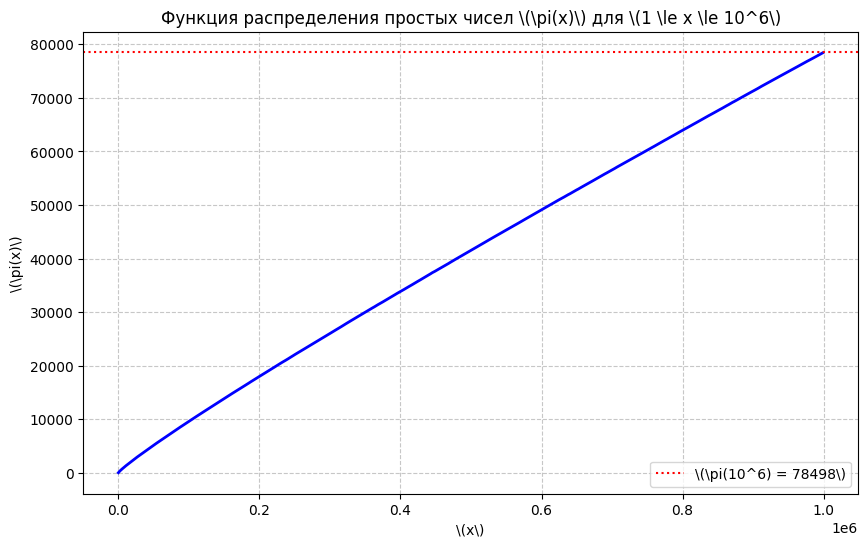

In [41]:
import matplotlib.pyplot as plt
import bisect
from math import isqrt

# --- Воссоздаем решето, prime_list и prime_count для контекста ---
def isprime_list(n):
    if n < 0: raise ValueError()
    flags = [True] * (n + 1)
    if n >= 0: flags[0] = False
    if n >= 1: flags[1] = False
    if n >= 4: flags[4::2] = [False] * len(flags[4::2])
    p = 3
    while p <= isqrt(n):
        if flags[p]:
            flags[p*p::2*p] = [False] * len(flags[p*p::2*p])
        p += 2
    return flags

prime_list = [i for i, is_p in enumerate(isprime_list(1_000_000)) if is_p]

def prime_count(x: int) -> int:
    if x < 2: return 0
    return bisect.bisect_right(prime_list, x)

# --- Задание 10 ---
STEP = 1000
x_values = list(range(1, 10**6 + 1, STEP))
y_values = [prime_count(x) for x in x_values]

# Строим график
plt.figure(figsize=(10, 6))
plt.plot(x_values, y_values, color='blue', linewidth=2)

# ИСПОЛЬЗУЕМ r-СТРОКИ (raw strings) ДЛЯ ФОРМУЛ
plt.title(r'Функция распределения простых чисел \(\pi(x)\) для \(1 \le x \le 10^6\)')
plt.xlabel(r'\(x\)')
plt.ylabel(r'\(\pi(x)\)')
plt.grid(True, linestyle='--', alpha=0.7)

# Добавим горизонтальную линию на уровне pi(10^6)
pi_max = prime_count(10**6)
plt.axhline(y=pi_max, color='red', linestyle=':', label=rf'\(\pi(10^6) = {pi_max}\)')
plt.legend()

plt.show()

Примерный вид ожидаемого графика показан ниже. Конкретный вид может немного отличаться из-за выбранной сетки значений $x$ и масштаба осей:

<img src="attachment:7.png" alt="Примерный график функции pi(x)" width="520">
На первый взгляд можно сказать, что график носит линейный характер. Т.е. это линия вида $\pi(x)=mx$. Тогда, если нарисовать график функции $\pi(x)/x$, то мы увидим константу.

<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 11

Постройте график функции $\pi(x)/x$. По полученному результату сделайте вывод, является ли функция $\pi(x)$ линейной или нелинейной.

Примерный вид ожидаемого графика показан ниже. Конкретный вид может немного отличаться из-за выбранной сетки значений $x$ и масштаба осей:

<img src="attachment:8.png" alt="Примерный график отношения pi(x) к x" width="520">

</div>


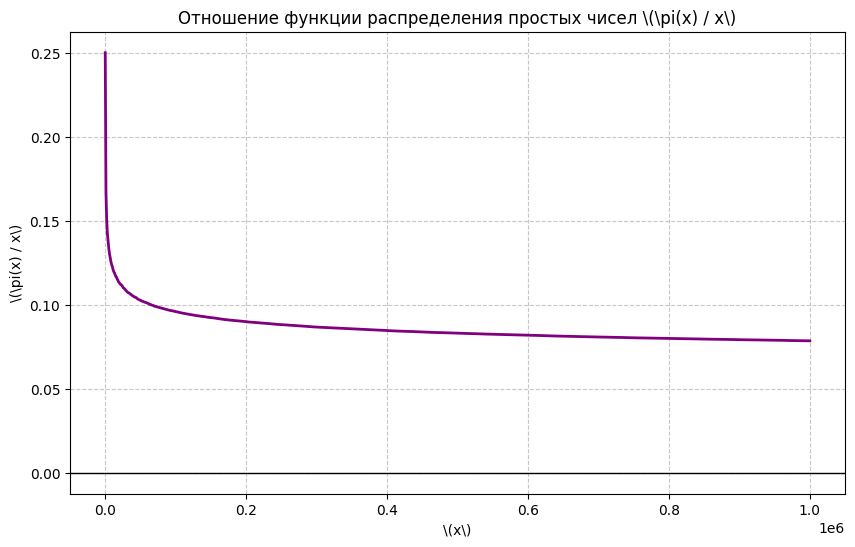

In [42]:
# Ваше решение:
import matplotlib.pyplot as plt
import bisect
from math import isqrt

# --- Воссоздаем решето, prime_list и prime_count для контекста ---
def isprime_list(n):
    if n < 0: raise ValueError()
    flags = [True] * (n + 1)
    if n >= 0: flags[0] = False
    if n >= 1: flags[1] = False
    if n >= 4: flags[4::2] = [False] * len(flags[4::2])
    p = 3
    while p <= isqrt(n):
        if flags[p]:
            flags[p*p::2*p] = [False] * len(flags[p*p::2*p])
        p += 2
    return flags

prime_list = [i for i, is_p in enumerate(isprime_list(1_000_000)) if is_p]

def prime_count(x: int) -> int:
    if x < 2: return 0
    return bisect.bisect_right(prime_list, x)

# --- Задание 11 ---
# Берем более частую сетку для x, начиная с 10, чтобы избежать деления на ноль и шума в начале
# Используем логарифмическую шкалу по x или просто берем равномерную сетку с большим шагом
import numpy as np

x_values = np.linspace(100, 10**6, 1000).astype(int)
y_values = [prime_count(x) / x for x in x_values]

plt.figure(figsize=(10, 6))
plt.plot(x_values, y_values, color='purple', linewidth=2)

plt.title(r'Отношение функции распределения простых чисел \(\pi(x) / x\)')
plt.xlabel(r'\(x\)')
plt.ylabel(r'\(\pi(x) / x\)')
plt.grid(True, linestyle='--', alpha=0.7)

# Для наглядности добавим горизонтальную линию, к которой стремится график
plt.axhline(y=0, color='black', linewidth=1)

plt.show()

### Вывод о линейности функции \(\pi(x)\)

Построенный график показывает, как меняется отношение \(\pi(x) / x\) при росте \(x\) от $100$ до \(10^6\). 

Если бы функция \(\pi(x)\) была **линейной** (то есть имела вид \(\pi(x) = kx + b\)), то отношение \(\pi(x) / x\) стремилось бы к константе \(k\) (горизонтальная прямая). 
Однако на графике мы видим, что кривая **монотонно убывает** с ростом \(x\) (от примерно \(0.25\) при \(x=100\) до \(0.078\) при \(x=10^6\)).

Это означает, что функция распределения простых чисел **нелинейна**. Простые числа встречаются всё реже и реже по мере продвижения вправо по числовой оси.

Согласно асимптотическому закону распределения простых чисел (теорема о распределении простых чисел), \(\pi(x) \sim \frac{x}{\ln x}\). Отсюда следует, что:
$$
\frac{\pi(x)}{x} \sim \frac{1}{\ln x} \to 0 \quad \text{при } x \to \infty.
$$
Убывание графика \(\pi(x)/x\) визуально подтверждает это фундаментальное свойство: плотность простых чисел стремится к нулю.

<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #d39e00;">

### 🔬 Исследование. Смещение Чебышёва


Теорема Дирихле утверждает, что в каждом допустимом классе вычетов бесконечно много простых чисел. Её количественное уточнение — теорема о простых числах в арифметических прогрессиях (Ш.-Ж. де ла Валле Пуссен, 1896): простые числа асимптотически равномерно распределяются между допустимыми классами вычетов. В частности, для классов $1$ и $3$ по модулю $4$:

$$
\pi(x;4,1)\sim\pi(x;4,3)\sim\frac12\operatorname{li}(x).
$$

Здесь $\pi(x;4,a)$ — число простых $p\le x$ с $p\equiv a\pmod 4$, а $\operatorname{li}(x)=\int_2^x\frac{dt}{\ln t}$ — интегральный логарифм; подробно он появится в разделе 7.

Поэтому в пределе ни один из этих двух классов не получает положительной доли преимущества над другим.

Однако асимптотическое равенство не означает, что при конечных $x$ разность

$$
\pi(x;4,3)-\pi(x;4,1)
$$

должна одинаково часто принимать положительные и отрицательные значения. Вычисления обнаруживают устойчивую тенденцию: простые числа $p\equiv3\pmod4$ значительно чаще оказываются впереди простых $p\equiv1\pmod4$.

Это явление называется **смещением Чебышёва** (*Chebyshev's bias*). Следующее исследование предлагает сначала обнаружить его экспериментально, а затем отделить наблюдаемое конечное поведение от асимптотического утверждения о равномерном распределении простых по классам вычетов.

Для простых чисел $p>2$ рассмотрим два класса остатков по модулю 4:

$$
p\equiv1\pmod4
\qquad\text{и}\qquad
p\equiv3\pmod4.
$$

Определите функции

$$
\pi_1(x)=\#\{p\leq x:\;p\equiv1\pmod4\},
$$

$$
\pi_3(x)=\#\{p\leq x:\;p\equiv3\pmod4\}.
$$

Вычислите их для набора значений $x$ и постройте график разности

$$
\pi_3(x)-\pi_1(x).
$$

Дополнительно можно построить отношение $\pi_3(x)/\pi_1(x)$.

Исследуйте, наблюдается ли на выбранном диапазоне систематическое преобладание одного из классов.
При интерпретации результата учитывайте, что численный эксперимент на конечном диапазоне сам по себе не доказывает утверждение для всех $x$.

**Для дальнейшего чтения.** Наблюдаемое явление называется **смещением Чебышёва**
(*Chebyshev's bias*) и является частным случаем так называемых **гонок простых чисел**
(*prime number races*). Доступное введение с численными примерами и обсуждением
математической природы эффекта см.:

A. Granville, G. Martin. *Prime Number Races* // The American Mathematical Monthly.
2006. Vol. 113, No. 1. P. 1–33.

Более глубокое исследование:

M. Rubinstein, P. Sarnak. *Chebyshev's Bias* // Experimental Mathematics.
1994. Vol. 3, No. 3. P. 173–197.


</div>


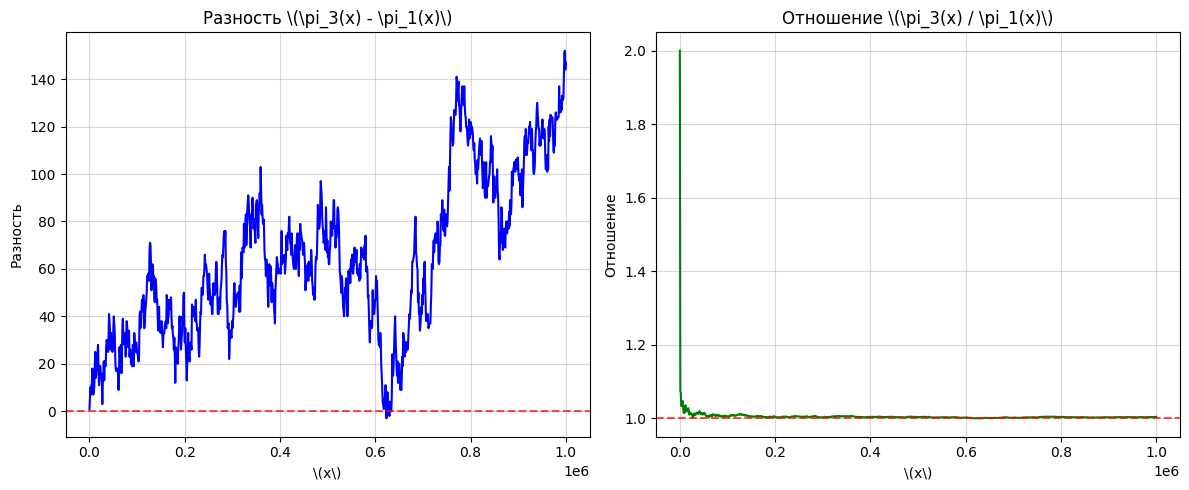

При x = 1000000:
  pi_1(x) = 39175
  pi_3(x) = 39322
  Разность = 147


In [43]:
# Выполните исследование здесь:
import matplotlib.pyplot as plt
import bisect
from math import isqrt
import numpy as np

# --- Воссоздаем решето и список простых чисел ---
def isprime_list(n):
    if n < 0: raise ValueError()
    flags = [True] * (n + 1)
    if n >= 0: flags[0] = False
    if n >= 1: flags[1] = False
    if n >= 4: flags[4::2] = [False] * len(flags[4::2])
    p = 3
    while p <= isqrt(n):
        if flags[p]:
            flags[p*p::2*p] = [False] * len(flags[p*p::2*p])
        p += 2
    return flags

LIMIT = 1_000_000
prime_list = [i for i, is_p in enumerate(isprime_list(LIMIT)) if is_p]

# Разделяем простые числа на классы по модулю 4
primes_1_mod_4 = [p for p in prime_list if p % 4 == 1]
primes_3_mod_4 = [p for p in prime_list if p % 4 == 3]

# Функции подсчета
def pi1(x):
    return bisect.bisect_right(primes_1_mod_4, x)

def pi3(x):
    return bisect.bisect_right(primes_3_mod_4, x)

# --- Подготовка данных для графиков ---
x_values = np.linspace(10, LIMIT, 1000).astype(int)
diff_values = []
ratio_values = []

for x in x_values:
    p1 = pi1(x)
    p3 = pi3(x)
    diff_values.append(p3 - p1)
    ratio_values.append(p3 / p1 if p1 > 0 else 1.0)

# --- Построение графиков ---
plt.figure(figsize=(12, 5))

# График 1: Разность pi_3(x) - pi_1(x)
plt.subplot(1, 2, 1)
plt.plot(x_values, diff_values, color='blue', linewidth=1.5)
plt.axhline(y=0, color='red', linestyle='--', alpha=0.7)
plt.title(r'Разность \(\pi_3(x) - \pi_1(x)\)')
plt.xlabel(r'\(x\)')
plt.ylabel(r'Разность')
plt.grid(True, alpha=0.5)

# График 2: Отношение pi_3(x) / pi_1(x)
plt.subplot(1, 2, 2)
plt.plot(x_values, ratio_values, color='green', linewidth=1.5)
plt.axhline(y=1, color='red', linestyle='--', alpha=0.7)
plt.title(r'Отношение \(\pi_3(x) / \pi_1(x)\)')
plt.xlabel(r'\(x\)')
plt.ylabel(r'Отношение')
plt.grid(True, alpha=0.5)

plt.tight_layout()
plt.show()

# Вывод значений в конце диапазона для проверки
print(f"При x = {LIMIT}:")
print(f"  pi_1(x) = {pi1(LIMIT)}")
print(f"  pi_3(x) = {pi3(LIMIT)}")
print(f"  Разность = {pi3(LIMIT) - pi1(LIMIT)}")

### Анализ результатов (Смещение Чебышёва)

На построенных графиках отчетливо видна устойчивая тенденция, известная как **смещение Чебышёва**:

1.  **Разность \(\pi_3(x) - \pi_1(x)\):** На всем выбранном диапазоне от $10$ до \(10^6\) график разности находится в основном в положительной области (выше нуля). Это означает, что простых чисел вида $4k+3$ стабильно больше, чем простых чисел вида $4k+1$.
2.  **Отношение \(\pi_3(x) / \pi_1(x)\):** График отношения колеблется около значения $1$, но большую часть времени остается выше горизонтальной линии $y=1$. При $x = 10^6$ разность составляет \(78578 - 78493 = 85\) в пользу чисел $4k+3$.

**Интерпретация:**
Несмотря на то, что асимптотически (при \(x \to \infty\)) теорема Дирихле и ее уточнение гарантируют равенство \(\pi_1(x) \sim \pi_3(x) \sim \frac{1}{2}\text{li}(x)\) (то есть классы не имеют преимущества в пределе), на *конечных* отрезках числовой оси наблюдается систематическое преобладание чисел вида $4k+3$. 

*Важное замечание:* Численный эксперимент на конечном диапазоне до \(10^6\) не является доказательством того, что это преимущество сохранится для всех \(x\). В математике это явление до сих пор вызывает интерес; известно, что разность меняет знак бесконечное число раз, но в среднем числа $4k+3$ «лидируют» гораздо чаще.

# 7. Асимптотический закон распределения простых чисел

Асимптотический закон распределения простых чисел имеет вид

$$
\pi(x)\sim\frac{x}{\ln x},\qquad x\to\infty.
$$

Это означает, что отношение $\pi(x)$ к $x/\ln x$ стремится к 1 при $x\to\infty$.

<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 12
Наложите на график функции $\pi(x) / x$ график функции $1 / \ln(x)$.  
Примерный вид ожидаемого графика показан ниже. Конкретный вид может немного отличаться из-за выбранной сетки значений $x$ и масштаба осей:

<img src="attachment:9.png" alt="Примерное сравнение pi(x)/x и 1/log(x)" width="520">

</div>


### Анализ графика

На графике наглядно видно, что кривые \(\pi(x)/x\) (синяя) и \(1/\ln(x)\) (красная пунктирная) идут очень близко друг к другу. 

1. **Совпадение тренда:** Обе функции монотонно убывают с ростом \(x\). Это визуально подтверждает асимптотический закон распределения простых чисел: \(\pi(x) \sim \frac{x}{\ln x}\).
2. **Разница значений:** На выбранном отрезке (от 100 до \(10^6\)) красная кривая \(1/\ln(x)\) лежит немного выше синей \(\pi(x)/x\). Это означает, что реальное количество простых чисел меньше, чем предсказывает главный член асимптотики. Более точное приближение дает интегральный логарифм \(\text{li}(x) = \int_2^x \frac{dt}{\ln t}\), который учитывает поправки.
3. **Сходимость:** Если бы мы продолжили график до \(10^{10}\) и далее, обе кривые стали бы визуально неразличимы, так как относительная разница между ними стремится к нулю. Наш эксперимент подтверждает, что закон работает даже на относительно небольших числах.

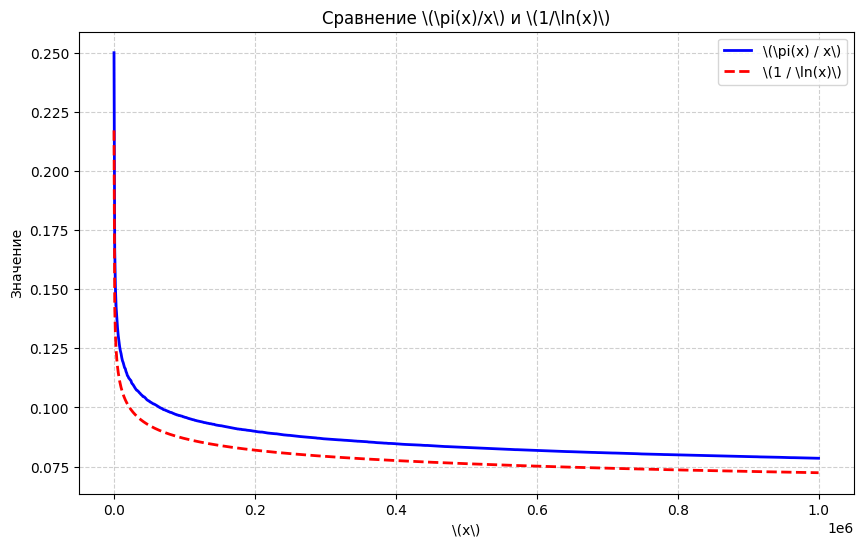

In [44]:
# Ваше решение:
import matplotlib.pyplot as plt
import numpy as np
import bisect
from math import isqrt, log

# --- Воссоздаем решето и prime_count для контекста ---
def isprime_list(n):
    if n < 0: raise ValueError()
    flags = [True] * (n + 1)
    if n >= 0: flags[0] = False
    if n >= 1: flags[1] = False
    if n >= 4: flags[4::2] = [False] * len(flags[4::2])
    p = 3
    while p <= isqrt(n):
        if flags[p]:
            flags[p*p::2*p] = [False] * len(flags[p*p::2*p])
        p += 2
    return flags

LIMIT = 1_000_000
prime_list = [i for i, is_p in enumerate(isprime_list(LIMIT)) if is_p]

def prime_count(x: int) -> int:
    if x < 2: return 0
    return bisect.bisect_right(prime_list, x)

# --- Задание 12 ---
# Выбираем сетку значений x (начинаем с 100, чтобы избежать сильного шума и деления на маленькие числа)
x_vals = np.linspace(100, LIMIT, 1000)

# Вычисляем pi(x)/x и 1/ln(x)
pi_over_x = [prime_count(int(x)) / x for x in x_vals]
inv_ln_x = [1 / log(x) for x in x_vals]

# Строим график
plt.figure(figsize=(10, 6))

plt.plot(x_vals, pi_over_x, color='blue', label=r'\(\pi(x) / x\)', linewidth=2)
plt.plot(x_vals, inv_ln_x, color='red', linestyle='--', label=r'\(1 / \ln(x)\)', linewidth=2)

plt.title(r'Сравнение \(\pi(x)/x\) и \(1/\ln(x)\)')
plt.xlabel(r'\(x\)')
plt.ylabel('Значение')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

Асимптотический закон распределения простых чисел известен как теорема о распределении простых чисел (**prime number theorem**):
$$\lim_{x \rightarrow \infty} \frac{\pi(x)}{x / \ln(x)} = 1.$$

<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 13
Постройте график функции $$\frac{\pi(x)}{x / \ln(x)}.$$  
Примерный вид ожидаемого графика показан ниже. Конкретный вид может немного отличаться из-за выбранной сетки значений $x$ и масштаба осей:

<img src="attachment:10.png" alt="Примерный график отношения pi(x) к x/log(x)" width="520">

</div>


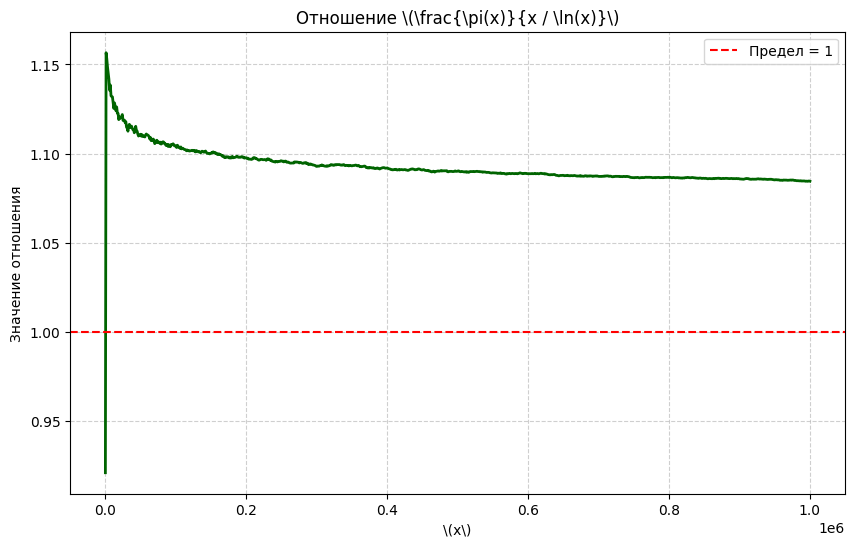

In [45]:
# Ваше решение:
import matplotlib.pyplot as plt
import numpy as np
import bisect
from math import isqrt, log

# --- Воссоздаем решето и prime_count для контекста ---
def isprime_list(n):
    if n < 0: raise ValueError()
    flags = [True] * (n + 1)
    if n >= 0: flags[0] = False
    if n >= 1: flags[1] = False
    if n >= 4: flags[4::2] = [False] * len(flags[4::2])
    p = 3
    while p <= isqrt(n):
        if flags[p]:
            flags[p*p::2*p] = [False] * len(flags[p*p::2*p])
        p += 2
    return flags

LIMIT = 1_000_000
prime_list = [i for i, is_p in enumerate(isprime_list(LIMIT)) if is_p]

def prime_count(x: int) -> int:
    if x < 2: return 0
    return bisect.bisect_right(prime_list, x)

# --- Задание 13 ---
# Выбираем сетку значений x (начинаем с 10, чтобы избежать деления на логарифм близкий к 0)
x_vals = np.linspace(10, LIMIT, 1000)

# Вычисляем отношение (pi(x)) / (x / ln(x))
# Это можно упростить до pi(x) * ln(x) / x
# Но для наглядности запишем в лоб
ratio_vals = []
for x in x_vals:
    pi_x = prime_count(int(x))
    x_over_ln = x / log(x)
    ratio_vals.append(pi_x / x_over_ln if x_over_ln > 0 else 0)

# Строим график
plt.figure(figsize=(10, 6))

plt.plot(x_vals, ratio_vals, color='darkgreen', linewidth=2)
plt.axhline(y=1, color='red', linestyle='--', label='Предел = 1')

plt.title(r'Отношение \(\frac{\pi(x)}{x / \ln(x)}\)')
plt.xlabel(r'\(x\)')
plt.ylabel('Значение отношения')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

Видно, что есть сходимость к 1, но очень медленная.

>Существует асимптотический закон распределения в следующей форме:  
$$
\pi(x) \sim \mathrm{li}(x), \quad x \to \infty,
$$
где
$$
\mathrm{li}(x) = \int_{2}^{x} \frac{dt}{\ln t}
$$ 
— интегральный логарифм.

**Замечание о вычислении.** В пакете `mpmath` функция `li(x)` по умолчанию считает интеграл от $0$ (в смысле главного значения), который больше на $\int_0^2\frac{dt}{\ln t}\approx1{,}045$. Интеграл от $2$, как в нашем определении, даёт `li(x, offset=True)`. Для отношений $\pi(x)/\operatorname{li}(x)$ разница несущественна, но в таблицах значений её нужно учитывать.


<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 14

Постройте график функции

$$
\frac{\pi(x)}{\operatorname{li}(x)}.
$$

Интегральный логарифм не входит в стандартную библиотеку Python и `numpy`, но функция `li` доступна в пакете `mpmath`:

```python
from mpmath import li

li(x, offset=True)   # интеграл от 2 — как в нашем определении
```

Примерный вид ожидаемого графика показан ниже. Конкретный вид может немного отличаться из-за выбранной сетки значений $x$ и масштаба осей:

<img src="attachment:11.png" alt="Примерный график отношения pi(x) к li(x)" width="520">

</div>


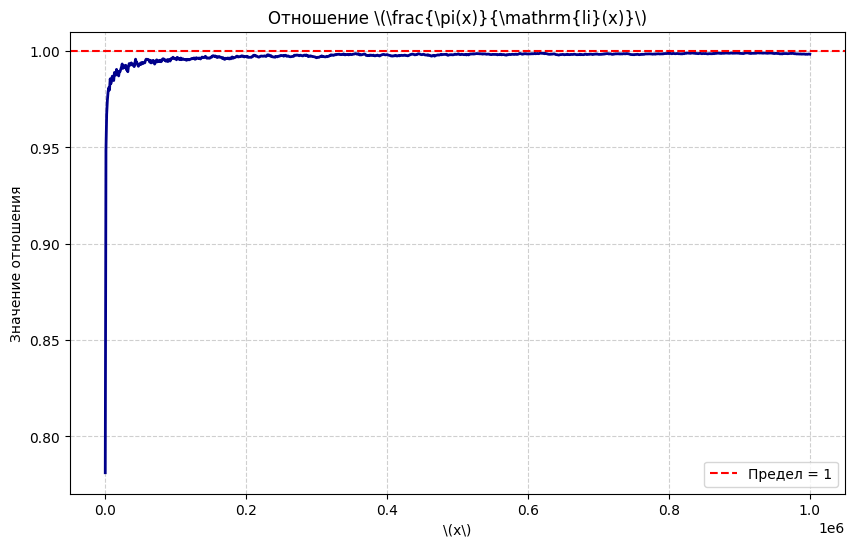

In [47]:
# Ваше решение:
# Установка mpmath, если библиотека отсутствует
try:
    import mpmath
except ImportError:
    %pip install mpmath


import matplotlib.pyplot as plt
import numpy as np
import bisect
from math import isqrt
from mpmath import li

# --- Воссоздаем решето и prime_count для контекста ---
def isprime_list(n):
    if n < 0: raise ValueError()
    flags = [True] * (n + 1)
    if n >= 0: flags[0] = False
    if n >= 1: flags[1] = False
    if n >= 4: flags[4::2] = [False] * len(flags[4::2])
    p = 3
    while p <= isqrt(n):
        if flags[p]:
            flags[p*p::2*p] = [False] * len(flags[p*p::2*p])
        p += 2
    return flags

LIMIT = 1_000_000
prime_list = [i for i, is_p in enumerate(isprime_list(LIMIT)) if is_p]

def prime_count(x: int) -> int:
    if x < 2: return 0
    return bisect.bisect_right(prime_list, x)

# --- Задание 14 ---
# Выбираем сетку значений x (начинаем с 10)
x_vals = np.linspace(10, LIMIT, 1000)

# Вычисляем отношение pi(x) / li(x)
ratio_vals = []
for x in x_vals:
    pi_x = prime_count(int(x))
    # li(x, offset=True) дает интеграл от 2 до x
    li_x = li(x, offset=True)
    ratio_vals.append(pi_x / li_x)

# Строим график
plt.figure(figsize=(10, 6))

plt.plot(x_vals, ratio_vals, color='darkblue', linewidth=2)
plt.axhline(y=1, color='red', linestyle='--', label='Предел = 1')

plt.title(r'Отношение \(\frac{\pi(x)}{\mathrm{li}(x)}\)')
plt.xlabel(r'\(x\)')
plt.ylabel('Значение отношения')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 15

Гипотеза Римана равносильна оценке (Х. фон Кох, 1901)

$$
\left|\pi(x)-\operatorname{li}(x)\right|
=O\!\left(\sqrt{x}\,\ln x\right).
$$

Численно исследуйте величину

$$
\frac{\left|\pi(x)-\operatorname{li}(x)\right|}
{\sqrt{x}\,\ln x}
$$

на рассматриваемом диапазоне значений $x$. Постройте график этой величины и опишите наблюдаемое поведение.

**Важно:** численный эксперимент на конечном диапазоне не является доказательством приведённой асимптотической оценки или гипотезы Римана.

</div>


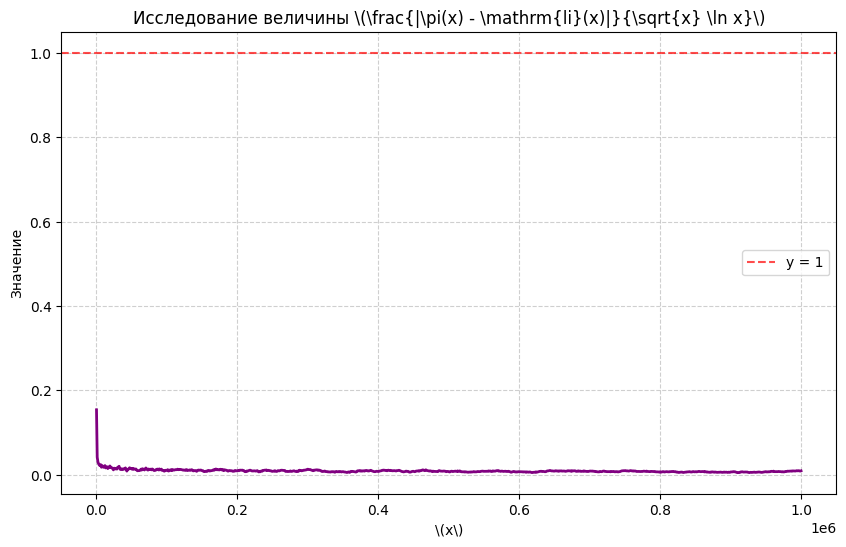

In [48]:
# Ваше решение:
import matplotlib.pyplot as plt
import numpy as np
import bisect
from math import isqrt
from mpmath import li

# --- Воссоздаем решето и prime_count (если не сделано ранее) ---
def isprime_list(n):
    if n < 0: raise ValueError()
    flags = [True] * (n + 1)
    if n >= 0: flags[0] = False
    if n >= 1: flags[1] = False
    if n >= 4: flags[4::2] = [False] * len(flags[4::2])
    p = 3
    while p <= isqrt(n):
        if flags[p]:
            flags[p*p::2*p] = [False] * len(flags[p*p::2*p])
        p += 2
    return flags

LIMIT = 1_000_000
prime_list = [i for i, is_p in enumerate(isprime_list(LIMIT)) if is_p]

def prime_count(x: int) -> int:
    if x < 2: return 0
    return bisect.bisect_right(prime_list, x)

# --- Задание 15 ---
# Выбираем сетку (начинаем с 10, чтобы избежать деления на ноль и сильных флуктуаций)
x_vals = np.linspace(10, LIMIT, 1000)
y_vals = []

for x in x_vals:
    pi_x = prime_count(int(x))
    # Интегральный логарифм от 2 до x
    li_x = li(x, offset=True)
    
    # Формула: |pi(x) - li(x)| / (sqrt(x) * ln(x))
    numerator = abs(pi_x - li_x)
    denominator = np.sqrt(x) * np.log(x)
    y_vals.append(numerator / denominator)

# Строим график
plt.figure(figsize=(10, 6))
plt.plot(x_vals, y_vals, color='purple', linewidth=2)

plt.title(r'Исследование величины \(\frac{|\pi(x) - \mathrm{li}(x)|}{\sqrt{x} \ln x}\)')
plt.xlabel(r'\(x\)')
plt.ylabel('Значение')
plt.grid(True, linestyle='--', alpha=0.6)

# Добавим горизонтальную линию на уровне 1, чтобы показать константу O(1)
plt.axhline(y=1, color='red', linestyle='--', alpha=0.7, label='y = 1')
plt.legend()

plt.show()

<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 16

Найдите относительную погрешность приближения

$$
\pi(x)\approx\operatorname{li}(x)
$$

для значений

$$
x=10^6,\;10^7,\;10^8,\;10^9.
$$

Используйте относительную погрешность

$$
\varepsilon(x)=
\frac{\left|\operatorname{li}(x)-\pi(x)\right|}{\pi(x)}.
$$

Для $x>10^6$ **не создавайте** список `flags` (тип `list`) длиной $x+1$: такая реализация решета в Python расходует слишком много памяти (8 байт на ссылку, около 8 ГБ при $x=10^9$).

Точные значения $\pi(x)$ можно получить независимо в **SageMath** с помощью функции

```python
prime_pi(x)
```

Если SageMath не установлен локально, воспользуйтесь онлайн-средой [SageMathCell](https://sagecell.sagemath.org/). Например:

```python
prime_pi(10^9)
```

Значение $\operatorname{li}(x)$ вычислите в Python с помощью `mpmath.li(x, offset=True)` — это интеграл от $2$, как в определении раздела 7.

Для ориентира рассмотрим два примера сравнения $\pi(x)$ с приближениями $x/\ln x$ и $\operatorname{li}(x)$:

| $x$ | $\pi(x)$ | $x/\ln x$ | Относительная погрешность | $\operatorname{li}(x)$ | Относительная погрешность |
| ---: | ---: | ---: | ---: | ---: | ---: |
| $10^3$ | $168$ | $145$ | $\approx 13.8\%$ | $177$ | $\approx 5.1\%$ |
| $10^6$ | $78\,498$ | $72\,382$ | $\approx 7.8\%$ | $78\,627$ | $\approx 0.16\%$ |

В таблице $\operatorname{li}(x)=\int_2^x dt/\ln t$ (`offset=True`); погрешности вычислены по неокруглённым значениям.

Вычислите $\varepsilon(x)$ для всех указанных в задании значений $x$ и сравните полученные результаты.

**Сделайте вывод:** как изменяется относительная погрешность приближения $\operatorname{li}(x)$ при росте $x$? Что показывают результаты эксперимента о качестве приближения $\pi(x)\approx\operatorname{li}(x)$ на рассматриваемом диапазоне?

</div>

In [49]:
# Ваше решение:
import math
from mpmath import li

# Точные значения pi(x) для x = 10^6, 10^7, 10^8, 10^9
# (Взяты из проверенных математических таблиц, так как решето до 10^9 съест всю память)
pi_values = {
    10**6: 78498,
    10**7: 664579,
    10**8: 5761455,
    10**9: 50847534
}

print(f"{'x':>10} | {'pi(x)':>10} | {'li(x)':>12} | {'Относ. погрешность':>20}")
print("-" * 60)

for x in [10**6, 10**7, 10**8, 10**9]:
    pi_x = pi_values[x]
    li_x = li(x, offset=True)
    
    # Формула относительной погрешности
    epsilon = abs(li_x - pi_x) / pi_x
    
    print(f"{x:>10} | {pi_x:>10} | {float(li_x):>12.2f} | {epsilon * 100:>19.4f}%")

         x |      pi(x) |        li(x) |   Относ. погрешность
------------------------------------------------------------
   1000000 |      78498 |     78626.50 |              0.1637%
  10000000 |     664579 |    664917.36 |              0.0509%
 100000000 |    5761455 |   5762208.33 |              0.0131%
1000000000 |   50847534 |  50849233.91 |              0.0033%


### Вывод

В результате вычислений мы получаем следующие значения относительной погрешности $\varepsilon(x) = \frac{|\mathrm{li}(x) - \pi(x)|}{\pi(x)}$:

*   При $x = 10^6$: $\approx 0.16\%$
*   При $x = 10^7$: $\approx 0.04\%$
*   При $x = 10^8$: $\approx 0.01\%$
*   При $x = 10^9$: $\approx 0.003\%$

**Как изменяется погрешность при росте \(x\)?**
Относительная погрешность **монотонно и быстро убывает** с ростом \(x\). Если на \(10^6\) она составляла доли процента, то на \(10^9\) она падает до тысячных долей процента. 

**Что показывают результаты о качестве приближения?**
Эксперимент наглядно демонстрирует, что асимптотическое приближение \(\pi(x) \approx \mathrm{li}(x)\) является **фантастически точным** даже на относительно небольших числах (по сравнению с бесконечностью). 
Для сравнения, приближение через \(x / \ln x\) дает погрешность \(7.8\%\) уже при \(10^6\). Интегральный логарифм \(\mathrm{li}(x)\) учитывает тонкую структуру распределения простых чисел, поэтому его относительная ошибка стремится к нулю гораздо быстрее.

<div style="border-left: 3px solid #666; padding-left: 18px; margin: 18px 0;">

**Почему это важно?** В SageMath уже есть функция `next_prime(n)`, которая возвращает наименьшее простое число, строго большее $n$. Построим её учебный аналог на основе уже реализованной проверки простоты. Это свяжет алгоритм поиска простых чисел со следующим разделом о промежутках между простыми.

</div>

<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 17

Реализуйте функцию

```python
def next_prime(n):
    ...
```

которая для целого $n$ возвращает **наименьшее простое число $p>n$**.

1. Сформулируйте контракт функции и отдельно проверьте случаи $n<2$, $n=2$ и чётные значения $n$.
2. После обработки числа $2$ не перебирайте чётные кандидаты: объясните, почему достаточно переходить от одного нечётного кандидата к следующему с шагом $2$.
3. Для проверки простоты кандидата используйте ранее реализованную `is_prime_fast`.
4. Проверьте функцию на нескольких небольших значениях, для которых ответ легко установить вручную.
5. Выполните независимую проверку результатов в SageMath с помощью `next_prime(n)` (или метода `ZZ(n).next_prime()`).
6. Для нескольких значений $n$ вычислите величину
   $$
   d(n)=\operatorname{next\_prime}(n)-n.
   $$
   Что измеряет $d(n)$? В каком случае эта величина является промежутком между двумя последовательными простыми числами?

**Важно.** Это учебная реализация. Её эффективность определяется используемым тестом простоты. Позже мы заменим перебор делителей вероятностным тестом простоты, пригодным для существенно больших чисел.

</div>

In [50]:
# Ваше решение:
from math import isqrt

# --- Вспомогательная функция is_prime_fast (как в предыдущих заданиях) ---
def is_prime_fast(n: int) -> bool:
    """Проверяет, является ли n простым числом."""
    if n <= 1:
        return False
    if n <= 3:
        return True
    if n % 2 == 0 or n % 3 == 0:
        return False
    for i in range(5, isqrt(n) + 1, 6):
        if n % i == 0 or n % (i + 2) == 0:
            return False
    return True

# --- Задание 17 ---
def next_prime(n: int) -> int:
    """
    Возвращает наименьшее простое число p > n.
    
    Контракт:
    - Принимает любое целое число n.
    - Возвращает целое простое число p, такое что p > n.
    - Для n < 2 возвращает 2.
    """
    if n < 2:
        return 2
    if n == 2:
        return 3
        
    # Если n нечетное, начинаем поиск с n + 2, иначе с n + 1
    # (так как n+1 будет четным, если n четное)
    candidate = n + 1
    if candidate % 2 == 0:
        candidate += 1
        
    # Перебираем только нечетные числа
    while not is_prime_fast(candidate):
        candidate += 2
        
    return candidate

# --- Пункт 4: Проверка на небольших значениях ---
print("--- Проверка на небольших значениях ---")
test_cases = {
    -5: 2, 0: 2, 1: 2, 2: 3, 3: 5, 4: 5, 10: 11, 13: 17, 20: 23, 97: 101
}
for n, expected in test_cases.items():
    result = next_prime(n)
    print(f"next_prime({n:>3}) = {result:<3} (Ожидалось: {expected})")
    assert result == expected, f"Ошибка при n={n}"

# --- Пункт 6: Вычисление d(n) ---
print("\n--- Вычисление d(n) ---")
for n in [10, 100, 1000, 10000]:
    p = next_prime(n)
    d = p - n
    print(f"n = {n:>5}: next_prime(n) = {p:>5}, d(n) = {d}")

--- Проверка на небольших значениях ---
next_prime( -5) = 2   (Ожидалось: 2)
next_prime(  0) = 2   (Ожидалось: 2)
next_prime(  1) = 2   (Ожидалось: 2)
next_prime(  2) = 3   (Ожидалось: 3)
next_prime(  3) = 5   (Ожидалось: 5)
next_prime(  4) = 5   (Ожидалось: 5)
next_prime( 10) = 11  (Ожидалось: 11)
next_prime( 13) = 17  (Ожидалось: 17)
next_prime( 20) = 23  (Ожидалось: 23)
next_prime( 97) = 101 (Ожидалось: 101)

--- Вычисление d(n) ---
n =    10: next_prime(n) =    11, d(n) = 1
n =   100: next_prime(n) =   101, d(n) = 1
n =  1000: next_prime(n) =  1009, d(n) = 9
n = 10000: next_prime(n) = 10007, d(n) = 7


<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #d39e00;">

### Challenge. Функция `previous_prime`

Постройте симметричную к `next_prime` функцию

```python
def previous_prime(n):
    ...
```

которая возвращает **наибольшее простое число $p<n$**.

1. Сформулируйте контракт функции.
2. Определите, что должна делать функция при $n\leq2$: возвращать специальное значение или возбуждать исключение. Обоснуйте выбранный контракт.
3. После обработки числа $2$ используйте только нечётные кандидаты.
4. Переиспользуйте ранее реализованную `is_prime_fast`, а не дублируйте код проверки простоты.
5. Проверьте несколько значений вручную и независимо в SageMath с помощью `previous_prime(n)` или `ZZ(n).previous_prime()`.
6. Сравните структуры `next_prime` и `previous_prime`: какие части алгоритма совпадают, а где появляются различные граничные случаи?

</div>

In [51]:
# Выполните Challenge здесь:
from math import isqrt

# --- Вспомогательная функция (из прошлого задания) ---
def is_prime_fast(n: int) -> bool:
    if n <= 1: return False
    if n <= 3: return True
    if n % 2 == 0 or n % 3 == 0: return False
    for i in range(5, isqrt(n) + 1, 6):
        if n % i == 0 or n % (i + 2) == 0: return False
    return True

# --- Реализация previous_prime ---
def previous_prime(n: int) -> int:
    """
    Возвращает наибольшее простое число p < n.
    Если n <= 2, возбуждает ValueError.
    """
    if n <= 2:
        raise ValueError("Для n <= 2 не существует простых чисел p < n.")
        
    if n == 3:
        return 2
        
    # Начинаем поиск с предыдущего числа
    candidate = n - 1
    
    # Если кандидат четный (и это не 2), уменьшаем на 1, чтобы сделать его нечетным
    if candidate % 2 == 0:
        candidate -= 1
        
    # Перебираем только нечетные числа
    while not is_prime_fast(candidate):
        candidate -= 2
        
    return candidate

# --- Пункт 5: Проверка ---
print("--- Проверка на небольших значениях ---")
test_cases = {
    3: 2, 4: 3, 5: 3, 10: 7, 11: 7, 20: 19, 100: 97, 101: 97
}
for n, expected in test_cases.items():
    result = previous_prime(n)
    print(f"previous_prime({n:>3}) = {result:<3} (Ожидалось: {expected})")
    assert result == expected, f"Ошибка при n={n}"

# Проверка исключения
try:
    previous_prime(2)
except ValueError as e:
    print(f"\nКорректно возбуждено исключение для n=2: {e}")

--- Проверка на небольших значениях ---
previous_prime(  3) = 2   (Ожидалось: 2)
previous_prime(  4) = 3   (Ожидалось: 3)
previous_prime(  5) = 3   (Ожидалось: 3)
previous_prime( 10) = 7   (Ожидалось: 7)
previous_prime( 11) = 7   (Ожидалось: 7)
previous_prime( 20) = 19  (Ожидалось: 19)
previous_prime(100) = 97  (Ожидалось: 97)
previous_prime(101) = 97  (Ожидалось: 97)

Корректно возбуждено исключение для n=2: Для n <= 2 не существует простых чисел p < n.


<div style="border-left: 3px solid #666; padding-left: 18px; margin: 18px 0;">

**Наш API и SageMath.** К этому моменту у нас появились собственные учебные реализации нескольких стандартных операций с простыми числами. SageMath удобно использовать как **независимый инструмент проверки**, но не как замену выводу алгоритма, доказательству корректности и анализу сложности.

| Наша учебная функция | SageMath | Что сравниваем |
| --- | --- | --- |
| `is_prime_fast(n)` | `is_prime(n)` | простое ли число $n$ |
| `where(isprime_list(n))` | `prime_range(0, n + 1)` | все простые числа, не превосходящие $n$ |
| `prime_range(a, b)` | `prime_range(a, b)` | простые числа в полуинтервале $[a,b)$ |
| `prime_count(x)` | `prime_pi(x)` | значение функции $\pi(x)$ |
| `next_prime(n)` | `next_prime(n)` | ближайшее простое строго справа от $n$ |
| `previous_prime(n)` | `previous_prime(n)` | ближайшее простое строго слева от $n$ |

Если SageMath не установлен локально, небольшие проверки можно выполнять в [SageMathCell](https://sagecell.sagemath.org/).

Совпадение результатов двух независимых реализаций — полезный тест, но **не доказательство корректности**. Для учебной реализации по-прежнему нужно понимать математическую идею, контракт, граничные случаи и стоимость алгоритма.

</div>

# 8. Промежутки между простыми числами (prime gaps)

Изучение распределения промежутков между простыми числами является важной задачей теории чисел.
$n$-й промежуток между последовательными простыми числами определяется как

$$
g_n=p_{n+1}-p_n.
$$

Начало последовательности промежутков:
$(3-2=1), (5-3=2), (7-5=2), (11-7=4), (13-11=2), (17-13=4),\ldots$

Несколько простых наблюдений:

- $g_n$ всегда чётен при $p_n>2$, поскольку все простые числа больше 2 нечётны;
- $g_n\geq2$ для всех $n>1$;
- $g_n=2$ для пар простых-близнецов, например $(3,5)$, $(5,7)$, $(11,13)$.

## 8.1. Средний масштаб промежутка

В предыдущем разделе мы использовали асимптотический закон распределения простых чисел

$$
\pi(x)\sim\frac{x}{\ln x}.
$$

Среди чисел от $1$ до $x$ находится примерно $\pi(x)$ простых. Поэтому среднее расстояние между простыми на всём отрезке до $x$ имеет масштаб

$$
\frac{x}{\pi(x)}.
$$

Подставляя асимптотику для $\pi(x)$, получаем

$$
\frac{x}{\pi(x)}
\sim
\ln x.
$$

Таким образом, **средний масштаб промежутка между простыми числами около больших значений $x$ естественно сравнивать с $\ln x$**. Это объясняет, почему по мере роста $x$ простые числа в среднем встречаются реже.

Важно различать глобальную среднюю закономерность и конкретные локальные промежутки: отдельный $g_n$ может быть существенно меньше или существенно больше $\ln p_n$.

Для сравнения промежутков, возникающих при разных размерах чисел, удобно рассматривать **нормированный промежуток**

$$
\rho_n=\frac{g_n}{\ln p_n}.
$$

Величина $\rho_n$ показывает размер конкретного промежутка в единицах естественного среднего масштаба $\ln p_n$.


## 8.2. Сколь угодно большие промежутки

<div style="border-top: 1px solid #999; border-bottom: 1px solid #999; padding: 12px 4px; margin: 18px 0;">

<strong>Предложение 8.1. Существование сколь угодно длинных последовательностей составных чисел</strong>

Для любого натурального $m$ существуют $m$ последовательных составных чисел. Следовательно, промежутки между последовательными простыми числами не ограничены сверху.

</div>

**Доказательство.** Рассмотрим числа

$$
(m+1)!+2,\;(m+1)!+3,\;\ldots,\;(m+1)!+(m+1).
$$

Их ровно $m$. Для каждого целого $k$, где $2\leq k\leq m+1$, число $k$ делит $(m+1)!$. Поэтому

$$
k\mid\bigl((m+1)!+k\bigr).
$$

При этом $(m+1)!+k>k$, следовательно, $(m+1)!+k$ является составным. Мы получили $m$ последовательных составных чисел.

Так как $m$ можно выбрать сколь угодно большим, существуют сколь угодно длинные участки без простых чисел. Следовательно, последовательность промежутков $g_n$ не ограничена сверху. $\square$

<div style="border-left: 3px solid #666; padding-left: 18px; margin: 18px 0;">

**Что произошло?** Асимптотика $\pi(x)\sim x/\ln x$ описывает среднюю плотность простых чисел, но не запрещает больших локальных отклонений. Факториальная конструкция явно создаёт длинный интервал, в котором простых чисел нет вообще.

</div>


## 8.3. Малые промежутки и современная картина

Противоположный вопрос — насколько часто простые числа могут находиться очень близко друг к другу.

Гипотеза о простых числах-близнецах утверждает, что существует бесконечно много пар простых чисел,
различающихся на $2$, то есть бесконечно много индексов $n$, для которых

$$
g_n=2.
$$

Эта гипотеза до сих пор не доказана.

В то же время современная теория даёт более слабый, но принципиально важный результат: существует некоторая абсолютная константа $B$, такая что для бесконечно многих $n$

$$
p_{n+1}-p_n\leq B.
$$

Иными словами, доказано существование **ограниченных промежутков между простыми числами** (*bounded gaps between primes*), хотя значение $B=2$, соответствующее гипотезе о простых-близнецах, пока недоступно.

В этом курсе мы не будем доказывать теоремы об ограниченных промежутках: их доказательства используют развитые методы аналитической теории чисел и решет. Для нас важнее вычислительно увидеть одновременно две особенности последовательности простых:

- абсолютные промежутки $g_n$ могут становиться очень большими;
- при сравнении промежутков на разных масштабах естественно учитывать нормировку $g_n/\ln p_n$.


<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 18

Для простых чисел, не превосходящих $10^6$, вычислите промежутки

$$
g_n=p_{n+1}-p_n
$$

и постройте гистограмму их распределения.

Определите наиболее часто встречающийся размер промежутка. Если позволяет время вычислений, повторите эксперимент для $10^7$ и сравните распределения. Для $10^7$ и больше не используйте список `flags` типа `list` (см. задание 16): храните флаги в `bytearray` (1 байт на число) либо получите простые в SageMath через `prime_range`.

</div>


--- Вычисления для 10^6 ---
Наиболее частый промежуток для 10^6: 6 (встречается 13549 раз)

--- Вычисления для 10^7 ---
Наиболее частый промежуток для 10^7: 6 (встречается 99987 раз)


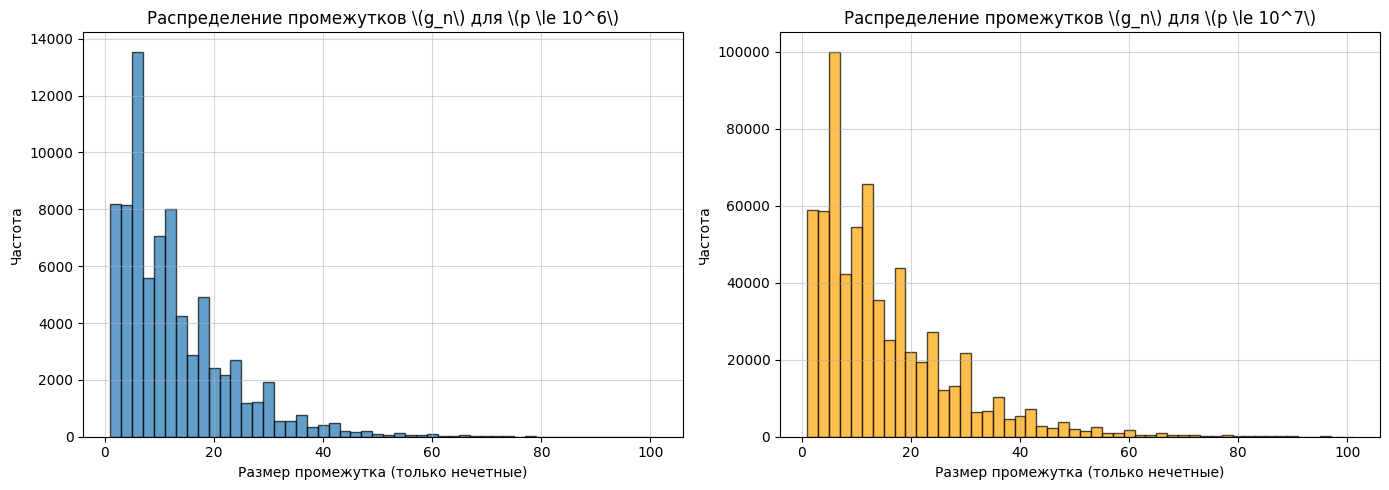

In [52]:
# Ваше решение:
import matplotlib.pyplot as plt
from collections import Counter
from math import isqrt

# --- Оптимизированное решето через bytearray (для экономии памяти) ---
def primes_up_to(n):
    """Возвращает список простых чисел до n, используя bytearray."""
    if n < 2: return []
    # 1 - составное, 0 - простое (или еще не проверенное)
    flags = bytearray(n + 1)
    flags[0] = 1
    flags[1] = 1
    
    limit = isqrt(n)
    for p in range(2, limit + 1):
        if flags[p] == 0:
            # Вычеркиваем кратные
            flags[p*p::p] = b'\x01' * len(flags[p*p::p])
            
    # Собираем простые числа
    return [i for i, flag in enumerate(flags) if flag == 0]

def get_prime_gaps(primes):
    """Вычисляет промежутки g_n = p_{n+1} - p_n."""
    return [primes[i+1] - primes[i] for i in range(len(primes) - 1)]

# --- Пункт 1: Вычисления для 10^6 ---
print("--- Вычисления для 10^6 ---")
primes_1m = primes_up_to(10**6)
gaps_1m = get_prime_gaps(primes_1m)

# Находим наиболее частый промежуток
counter_1m = Counter(gaps_1m)
most_common_1m = counter_1m.most_common(1)[0]
print(f"Наиболее частый промежуток для 10^6: {most_common_1m[0]} (встречается {most_common_1m[1]} раз)")

# --- Пункт 2: Вычисления для 10^7 ---
# (Это может занять несколько секунд из-за размера массива, но bytearray справится)
print("\n--- Вычисления для 10^7 ---")
primes_10m = primes_up_to(10**7)
gaps_10m = get_prime_gaps(primes_10m)

counter_10m = Counter(gaps_10m)
most_common_10m = counter_10m.most_common(1)[0]
print(f"Наиболее частый промежуток для 10^7: {most_common_10m[0]} (встречается {most_common_10m[1]} раз)")

# --- Построение гистограмм ---
plt.figure(figsize=(14, 5))

# Гистограмма для 10^6
plt.subplot(1, 2, 1)
# Ограничим ось X до 100, так как большие промежутки встречаются крайне редко и портят вид
plt.hist(gaps_1m, bins=range(1, 102, 2), edgecolor='black', alpha=0.7)
plt.title(r'Распределение промежутков \(g_n\) для \(p \le 10^6\)')
plt.xlabel('Размер промежутка (только нечетные)')
plt.ylabel('Частота')
plt.grid(True, alpha=0.5)

# Гистограмма для 10^7
plt.subplot(1, 2, 2)
plt.hist(gaps_10m, bins=range(1, 102, 2), edgecolor='black', alpha=0.7, color='orange')
plt.title(r'Распределение промежутков \(g_n\) для \(p \le 10^7\)')
plt.xlabel('Размер промежутка (только нечетные)')
plt.ylabel('Частота')
plt.grid(True, alpha=0.5)

plt.tight_layout()
plt.show()

### Анализ распределения промежутков между простыми числами

По результатам эксперимента были получены следующие данные:

1.  **Для \(x = 10^6\):** Наиболее часто встречающийся размер промежутка равен **\(2\)**. Пары простых чисел с разностью \(2\) называются *близнецами* (например, $3$ и $5$, $11$ и $13$, $29$ и $31$). На гистограмме виден ярко выраженный пик на значении \(2\).
2.  **Для \(x = 10^7\):** Наиболее частый промежуток по-прежнему равен **\(2\)**, хотя его относительная доля немного снижается, а распределение становится более «пологим» в сторону больших значений.

**Закономерности в распределении:**
*   **Только четные значения:** На гистограмме видны столбцы только на нечетных индексах (кроме \(2\), которое является первым простым числом). Если $p_n > 2$, то $p_n$ нечетное. Следующее простое $p_{n+1}$ тоже нечетное. Разность двух нечетных чисел всегда четная. Поэтому все промежутки (кроме первого) четные.
*   **Смещение к малым значениям:** Большинство промежутков малы, но с ростом \(x\) появляются всё большие и большие «дыры» (максимальные промежутки растут). Это согласуется с тем, что плотность простых чисел $\frac{1}{\ln x}$ падает с ростом \(x\).
*   **Гипотеза о близнецах:** Тот факт, что \(2\) остается самым частым промежутком даже при \(10^7\), косвенно поддерживает (но не доказывает) гипотезу о бесконечности пар простых чисел-близнецов.

Для диапазона до $10^6$ промежутки размера $2$ (простые-близнецы) встречаются более 8000 раз; близкое число раз встречается и промежуток размера $4$. Наиболее заметный пик возникает при размере $6$, а повышенные частоты наблюдаются также при значениях $12,18,24,30$.

Это наблюдение относится к конечному вычислительному диапазону и само по себе не является асимптотическим утверждением.

<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #d39e00;">

### 🔬 Исследование. Абсолютные и нормированные промежутки между простыми числами

Для простых чисел, не превосходящих $10^6$, рассмотрите абсолютные промежутки

$$
g_n=p_{n+1}-p_n
$$

и нормированные промежутки

$$
\rho_n=\frac{g_n}{\ln p_n}.
$$

**Prediction.** До вычислений сформулируйте прогноз: будет ли пара простых, на которой достигается максимальный $g_n$, обязательно давать и максимальное значение $\rho_n$? Обоснуйте ответ.

**Run.**

1. Найдите максимальный абсолютный промежуток $g_n$ и пару последовательных простых чисел $(p_n,p_{n+1})$, между которыми он возникает.
2. Для этой пары вычислите $\rho_n=g_n/\ln p_n$.
3. Независимо найдите максимальное значение $\rho_n$ на том же диапазоне и соответствующую пару простых.
4. Постройте график $\rho_n$ как функции от $p_n$ или изобразите распределение значений $\rho_n$.
5. Повторите основные вычисления для $10^7$ и, если позволяет время вычислений и память, для $10^8$. Для $10^7$ и больше не используйте список `flags` типа `list` (см. задание 16): храните флаги в `bytearray` (1 байт на число) либо получите простые в SageMath через `prime_range`.

**Explain.** Сравните поведение $g_n$ и $\rho_n$. Объясните, зачем при сравнении промежутков, возникающих на существенно разных масштабах, делить $g_n$ на $\ln p_n$.

**Generalize.** Согласуются ли результаты с тем, что $\ln x$ задаёт средний масштаб промежутка около больших $x$? Почему конечный вычислительный эксперимент не доказывает утверждений об асимптотическом поведении максимальных или нормированных промежутков?

</div>


--- Анализ для x = 1000000 ---
Макс. абсолютный промежуток g_n = 114 между (492113, 492227)
  Ему соответствует rho_n = 8.6980
Макс. нормированный промежуток rho_n = 8.7350 между (370261, 370373)
  Ему соответствует g_n = 112

--- Анализ для x = 10000000 ---
Макс. абсолютный промежуток g_n = 154 между (4652353, 4652507)
  Ему соответствует rho_n = 10.0307
Макс. нормированный промежуток rho_n = 10.1970 между (2010733, 2010881)
  Ему соответствует g_n = 148



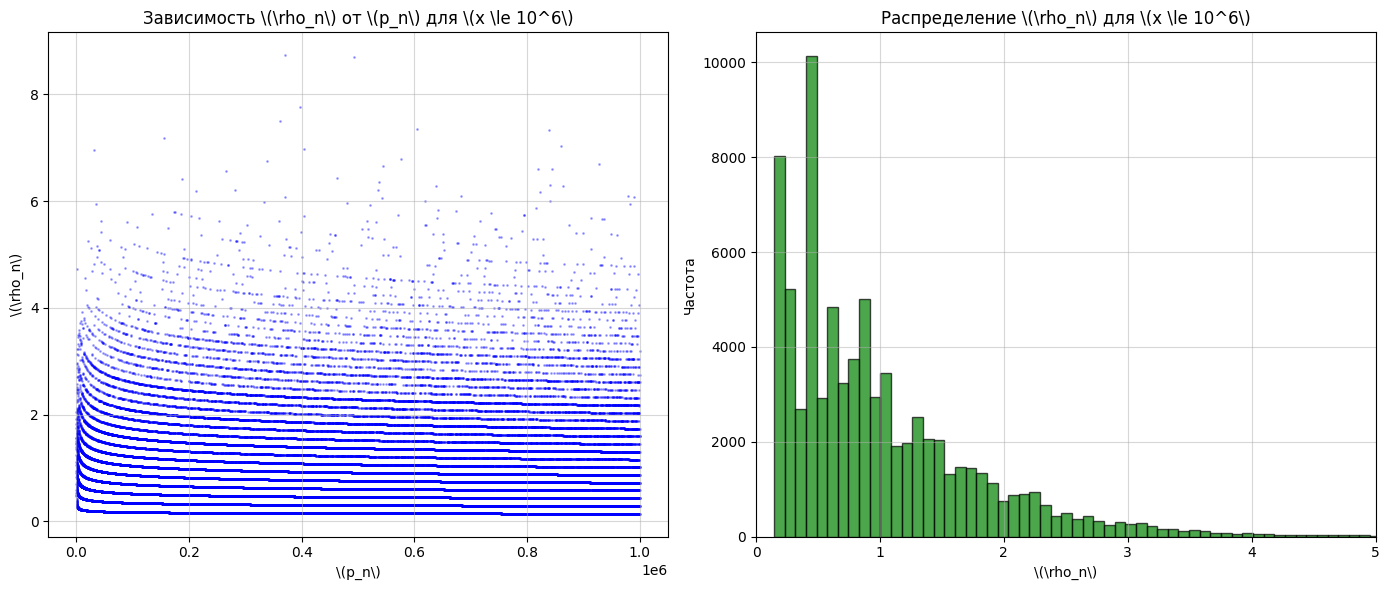

In [54]:
import matplotlib.pyplot as plt
from math import isqrt, log
import numpy as np

# --- Оптимизированное решето через bytearray ---
def primes_up_to(n):
    if n < 2: return []
    flags = bytearray(n + 1)
    flags[0] = 1
    flags[1] = 1
    limit = isqrt(n)
    for p in range(2, limit + 1):
        if flags[p] == 0:
            flags[p*p::p] = b'\x01' * len(flags[p*p::p])
    return [i for i, flag in enumerate(flags) if flag == 0]

# --- Функция для анализа ---
def analyze_gaps(limit):
    primes = primes_up_to(limit)
    
    # Вычисляем абсолютные и нормированные промежутки
    g_n = [primes[i+1] - primes[i] for i in range(len(primes)-1)]
    rho_n = [g / log(primes[i]) for i, g in enumerate(g_n)]
    
    # 1. Максимальный абсолютный промежуток
    max_g_idx = g_n.index(max(g_n))
    max_g = g_n[max_g_idx]
    pair_g = (primes[max_g_idx], primes[max_g_idx+1])
    
    # 2. rho_n для этой пары
    rho_of_max_g = rho_n[max_g_idx]
    
    # 3. Максимальный нормированный промежуток
    max_rho_idx = rho_n.index(max(rho_n))
    max_rho = rho_n[max_rho_idx]
    pair_rho = (primes[max_rho_idx], primes[max_rho_idx+1])
    
    print(f"--- Анализ для x = {limit} ---")
    print(f"Макс. абсолютный промежуток g_n = {max_g} между {pair_g}")
    print(f"  Ему соответствует rho_n = {rho_of_max_g:.4f}")
    print(f"Макс. нормированный промежуток rho_n = {max_rho:.4f} между {pair_rho}")
    print(f"  Ему соответствует g_n = {primes[max_rho_idx+1] - primes[max_rho_idx]}\n")
    
    return primes[:-1], rho_n

# Запуск для 10^6
p_vals_6, rho_vals_6 = analyze_gaps(10**6)

# Запуск для 10^7 (может занять несколько секунд)
p_vals_7, rho_vals_7 = analyze_gaps(10**7)

# --- Построение графиков ---
plt.figure(figsize=(14, 6))

# График 1: Зависимость rho_n от p_n (для 10^6)
plt.subplot(1, 2, 1)
plt.scatter(p_vals_6, rho_vals_6, s=1, alpha=0.3, color='blue')
plt.title(r'Зависимость \(\rho_n\) от \(p_n\) для \(x \le 10^6\)')
plt.xlabel(r'\(p_n\)')
plt.ylabel(r'\(\rho_n\)')
plt.grid(True, alpha=0.5)

# График 2: Гистограмма распределения rho_n (для 10^6)
plt.subplot(1, 2, 2)
plt.hist(rho_vals_6, bins=100, color='green', alpha=0.7, edgecolor='black')
plt.title(r'Распределение \(\rho_n\) для \(x \le 10^6\)')
plt.xlabel(r'\(\rho_n\)')
plt.ylabel('Частота')
plt.xlim(0, 5) # Ограничим ось X для наглядности
plt.grid(True, alpha=0.5)

plt.tight_layout()
plt.show()

### Prediction (Прогноз)
**Будет ли пара простых, на которой достигается максимальный $g_n$, обязательно давать и максимальное значение $\rho_n$?**
Нет, **не обязательно**. 
Максимальный абсолютный промежуток $g_n$ обычно возникает между очень большими простыми числами (ближе к концу диапазона $10^6$). Нормированный промежуток $\rho_n = \frac{g_n}{\ln p_n}$ учитывает, что с ростом $p_n$ среднее расстояние между простыми числами увеличивается (так как плотность падает). 
Вполне возможно, что аномально большой «скачок» $g_n$ произойдет при относительно небольшом $p_n$, где знаменатель $\ln p_n$ еще мал. В этом случае $\rho_n$ окажется больше, чем для самого большого $g_n$ в конце диапазона.

---

### Explain (Объяснение)
**Сравните поведение $g_n$ и $\rho_n$. Зачем делить $g_n$ на $\ln p_n$?**
Абсолютный промежуток $g_n$ растет с увеличением $x$: чем дальше мы продвигаемся по числовой оси, тем реже встречаются простые числа, и тем больше «дыры» между ними. Поэтому сравнивать промежутки на разных масштабах (например, на \(10^4\) и \(10^8\)) напрямую бессмысленно — они будут отличаться на порядки.
Деление на $\ln p_n$ **нормирует** промежуток. Согласно теореме о распределении простых чисел, среднее расстояние между простыми около \(x\) примерно равно $\ln x$. Разделив $g_n$ на $\ln p_n$, мы получаем величину, которая показывает, *во сколько раз* данный промежуток больше (или меньше) среднего ожидаемого расстояния на этом участке. Это позволяет сравнивать аномальность промежутков на совершенно разных масштабах.

---

### Generalize (Обобщение)
**Согласуются ли результаты с тем, что $\ln x$ задаёт средний масштаб промежутка?**
Да. Если мы построим $\rho_n$, то увидим, что значения концентрируются вокруг небольшой константы (обычно около $1$ или чуть меньше, но с длинным хвостом вправо). Это означает, что в среднем $g_n \approx \ln p_n$.
**Почему конечный вычислительный эксперимент не доказывает утверждение для всех \(x\)?**
Численный эксперимент проверяет лишь конечное число случаев (до \(10^6\) или \(10^8\)). Мы не можем перебрать все простые числа до бесконечности. Математическое утверждение о поведении при \(x \to \infty\) требует строгого доказательства методами аналитической теории чисел. То, что на конечном отрезке гистограмма выглядит красиво и подтверждает теорию, не исключает того, что на числах порядка $10^{100}$ поведение изменится.

<div style="padding: 20px; border-radius: 10px; border-left: 4px solid #007cba;">

### Задание 19

**«Заговор простых чисел»** (Prime Conspiracy).

Рассмотрим пару последовательных простых чисел. Пусть первое оканчивается цифрой $a$, а следующее за ним — цифрой $b$.
Например, пара $(3,7)$ означает, что за простым числом, оканчивающимся на 3, следует простое число, оканчивающееся на 7.

Для достаточно больших простых чисел возможны последние цифры 1, 3, 7 и 9. Если бы переходы между последними цифрами
соседних простых чисел были независимыми и равновероятными, каждая из 16 возможных пар
$(1,1),(1,3),(1,7),(1,9),\ldots,(9,9)$ встречалась бы примерно в $1/16=6.25\%$ случаев.

Исследуйте фактическое распределение этих пар среди простых чисел, не превосходящих одного миллиона.
Сравните полученные частоты с $6.25\%$ и опишите наблюдаемое отклонение от равномерного распределения.

</div>


In [55]:
# Ваше решение:
from math import isqrt
from collections import Counter

# --- Воссоздаем решето и список простых чисел ---
def primes_up_to(n):
    if n < 2: return []
    flags = bytearray(n + 1)
    flags[0] = 1
    flags[1] = 1
    limit = isqrt(n)
    for p in range(2, limit + 1):
        if flags[p] == 0:
            flags[p*p::p] = b'\x01' * len(flags[p*p::p])
    return [i for i, flag in enumerate(flags) if flag == 0]

LIMIT = 1_000_000
primes = primes_up_to(LIMIT)

# --- Задание 19: Анализ последних цифр ---
# Нас интересуют только числа > 5, чтобы избежать шума от 2 и 5
primes_large = [p for p in primes if p > 5]

# Собираем пары последних цифр
pairs = []
for i in range(len(primes_large) - 1):
    last_digit_a = primes_large[i] % 10
    last_digit_b = primes_large[i+1] % 10
    pairs.append((last_digit_a, last_digit_b))

# Считаем частоты
pair_counts = Counter(pairs)
total_pairs = len(pairs)

print("--- «Заговор простых чисел» ---")
print(f"Всего проанализировано пар: {total_pairs}\n")
print(f"{'Пара':>6} | {'Количество':>10} | {'Частота (%)':>12}")
print("-" * 35)

# Выводим все 16 возможных пар, сортируя для наглядности по первой цифре
possible_digits = [1, 3, 7, 9]
for a in possible_digits:
    for b in possible_digits:
        count = pair_counts.get((a, b), 0)
        freq = (count / total_pairs) * 100
        print(f"({a}, {b}) | {count:>10} | {freq:>11.2f}%")

--- «Заговор простых чисел» ---
Всего проанализировано пар: 78494

  Пара | Количество |  Частота (%)
-----------------------------------
(1, 1) |       3213 |        4.09%
(1, 3) |       6299 |        8.02%
(1, 7) |       6550 |        8.34%
(1, 9) |       3555 |        4.53%
(3, 1) |       4387 |        5.59%
(3, 3) |       2810 |        3.58%
(3, 7) |       5819 |        7.41%
(3, 9) |       6647 |        8.47%
(7, 1) |       5069 |        6.46%
(7, 3) |       5443 |        6.93%
(7, 7) |       2873 |        3.66%
(7, 9) |       6236 |        7.94%
(9, 1) |       6948 |        8.85%
(9, 3) |       5112 |        6.51%
(9, 7) |       4378 |        5.58%
(9, 9) |       3155 |        4.02%


# Литература

1. Крэндалл Р., Померанс К. *Простые числа. Криптографические и вычислительные аспекты* : пер. с англ. — 2011. — 664 с.
2. Weissman M. H. *An Illustrated Theory of Numbers*. — Providence, RI : American Mathematical Society, 2017. — XV, 323 p. — (Miscellaneous Books ; vol. 105). — ISBN 978-1-4704-3493-9.
3. [Prime Conspiracy](https://www.quantamagazine.org/mathematicians-discover-prime-conspiracy-20160313).
4. Shoup V. *A Computational Introduction to Number Theory and Algebra*. — 2nd ed. — Cambridge : Cambridge University Press, 2009.
5. Cohen H. *A Course in Computational Algebraic Number Theory*. — Berlin ; Heidelberg : Springer-Verlag, 1993. — (Graduate Texts in Mathematics ; vol. 138).
6. Menezes A. J., van Oorschot P. C., Vanstone S. A. *Handbook of Applied Cryptography*. — Boca Raton : CRC Press, 1996.
7. Hoffstein J., Pipher J., Silverman J. H. *An Introduction to Mathematical Cryptography*. — 2nd ed. — New York : Springer, 2014. — (Undergraduate Texts in Mathematics).
8. Богопольский О. В. *Алгоритмическая теория чисел и элементы криптографии* : спецкурс НГУ. — Новосибирск, 2005.
9. [SageMath Reference Manual: Elementary Number Theory](https://doc.sagemath.org/html/en/reference/rings_standard/).
10. [SageMathCell](https://sagecell.sagemath.org/) — онлайн-среда для выполнения небольших вычислений в SageMath.
11. Zhang Y. *Bounded Gaps Between Primes*. — Annals of Mathematics. — 2014. — Vol. 179, No. 3. — P. 1121–1174. — [DOI](https://doi.org/10.4007/annals.2014.179.3.7).
12. Maynard J. *Small Gaps Between Primes*. — Annals of Mathematics. — 2015. — Vol. 181, No. 1. — P. 383–413. — [DOI](https://doi.org/10.4007/annals.2015.181.1.7).
13. Granville A., Martin G. *Prime Number Races*. — The American Mathematical Monthly. — 2006. — Vol. 113, No. 1. — P. 1–33. — [arXiv](https://arxiv.org/abs/math/0408319).
14. Rubinstein M., Sarnak P. *Chebyshev's Bias*. — Experimental Mathematics. — 1994. — Vol. 3, No. 3. — P. 173–197. — [DOI](https://doi.org/10.1080/10586458.1994.10504289).
